In [2]:
import os
import numpy as np
import pandas as pd

from scipy.io import loadmat
from scipy.signal import cheby1, sosfiltfilt, welch
from scipy.stats import skew, kurtosis, spearmanr

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from scipy.spatial.distance import pdist, squareform

import pywt

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### **PHASE 1: DATA, DEFINITIONS, ETC**

In [4]:
# ============================================================
# 1.1 PATHS
# ============================================================

raw_folder = '/content/drive/MyDrive/Journal/raw_data'

scales_path = '/content/drive/MyDrive/Journal/scales.csv'

output_feature_path = (
    '/content/drive/MyDrive/Journal/raw_data/'
    'SAM40_trial1_features.csv'
)

output_cluster_path = (
    '/content/drive/MyDrive/Journal/raw_data/'
    'SAM40_trial1_clustered.csv'
)

# ============================================================
# 1.2 CHANNELS
# ============================================================

channels = [
    'Cz', 'Fz', 'Fp1', 'F7', 'F3', 'FC1', 'C3', 'FC5',
    'FT9', 'T7', 'CP5', 'CP1', 'P3', 'P7', 'PO9', 'O1',
    'Pz', 'Oz', 'O2', 'PO10', 'P8', 'P4', 'CP2', 'CP6',
    'T8', 'FT10', 'FC6', 'C4', 'FC2', 'F4', 'F8', 'Fp2'
]

fs = 128

# ============================================================
# 1.3 STRESS TASKS
# ============================================================

task_files = {
    'Arithmetic': 'Arithmetic',
    'Mirror_image': 'Mirror_image',
    'Stroop': 'Stroop',
    'Relaxation': 'Relax'
}

print(task_files)

{'Arithmetic': 'Arithmetic', 'Mirror_image': 'Mirror_image', 'Stroop': 'Stroop', 'Relaxation': 'Relax'}


In [5]:
# ============================================================
# 1.4 LOAD SAM40 RAW EEG DATA
# ============================================================

all_data = []

for subject in range(1, 41):

    for task_name, file_prefix in task_files.items():

        file_name = f'{file_prefix}_sub_{subject}_trial1.mat'
        file_path = os.path.join(raw_folder, file_name)

        if not os.path.exists(file_path):

            print(f'File not found: {file_name}')
            continue

        # ----------------------------------------------------
        # Load MATLAB file
        # ----------------------------------------------------

        mat_data = loadmat(file_path)

        raw = mat_data['Data']

        # ----------------------------------------------------
        # Verify dimensions
        # ----------------------------------------------------

        if raw.shape != (32, 3200):

            print(
                f'Warning: {file_name} has shape {raw.shape}'
            )

            continue

        # ----------------------------------------------------
        # Transpose
        # 32 × 3200 → 3200 × 32
        # ----------------------------------------------------

        eeg = raw.T

        # ----------------------------------------------------
        # Create dataframe
        # ----------------------------------------------------

        df = pd.DataFrame(
            eeg,
            columns=channels
        )

        df['Sample'] = np.arange(3200)

        df['Time'] = np.arange(3200) / fs

        df['Subject'] = subject

        df['Trial'] = 1

        df['Task'] = task_name

        all_data.append(df)

        print(
            f'Loaded: Subject {subject:02d} | {task_name}'
        )


# ------------------------------------------------------------
# Combine all data
# ------------------------------------------------------------

raw_all = pd.concat(
    all_data,
    ignore_index=True
)

print("\n====================================")
print("RAW EEG DATA")
print("====================================")

print("Shape:", raw_all.shape)

print(
    "Number of subjects:",
    raw_all['Subject'].nunique()
)

print(
    "Number of EEG channels:",
    len(channels)
)

print("\nTasks:")
print(raw_all['Task'].value_counts())

Loaded: Subject 01 | Arithmetic
Loaded: Subject 01 | Mirror_image
Loaded: Subject 01 | Stroop
Loaded: Subject 01 | Relaxation
Loaded: Subject 02 | Arithmetic
Loaded: Subject 02 | Mirror_image
Loaded: Subject 02 | Stroop
Loaded: Subject 02 | Relaxation
Loaded: Subject 03 | Arithmetic
Loaded: Subject 03 | Mirror_image
Loaded: Subject 03 | Stroop
Loaded: Subject 03 | Relaxation
Loaded: Subject 04 | Arithmetic
Loaded: Subject 04 | Mirror_image
Loaded: Subject 04 | Stroop
Loaded: Subject 04 | Relaxation
Loaded: Subject 05 | Arithmetic
Loaded: Subject 05 | Mirror_image
Loaded: Subject 05 | Stroop
Loaded: Subject 05 | Relaxation
Loaded: Subject 06 | Arithmetic
Loaded: Subject 06 | Mirror_image
Loaded: Subject 06 | Stroop
Loaded: Subject 06 | Relaxation
Loaded: Subject 07 | Arithmetic
Loaded: Subject 07 | Mirror_image
Loaded: Subject 07 | Stroop
Loaded: Subject 07 | Relaxation
Loaded: Subject 08 | Arithmetic
Loaded: Subject 08 | Mirror_image
Loaded: Subject 08 | Stroop
Loaded: Subject 08 | Rel


RAW EEG DISTRIBUTION BY TASK
Task
Arithmetic      128000
Mirror_image    128000
Relaxation      128000
Stroop          128000
Name: count, dtype: int64


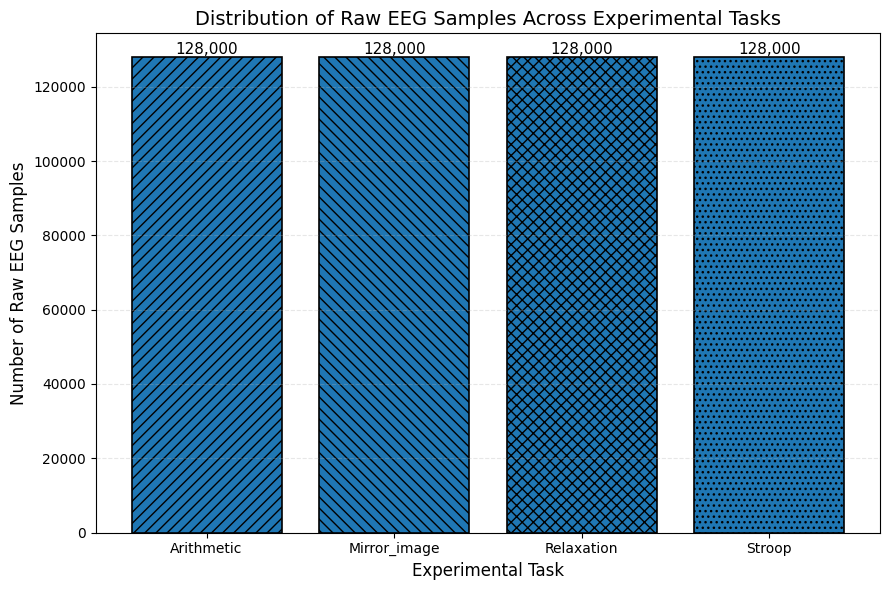

In [6]:
# ============================================================
# 1.5 VISUALIZE RAW EEG DATA DISTRIBUTION BY TASK
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# COUNT RAW EEG SAMPLES BY TASK
# ------------------------------------------------------------

raw_task_counts = (
    raw_all['Task']
    .value_counts()
    .sort_index()
)

print("\n====================================")
print("RAW EEG DISTRIBUTION BY TASK")
print("====================================")

print(raw_task_counts)

# ------------------------------------------------------------
# BAR CHART WITH DIFFERENT HATCH PATTERNS
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

hatches = ['///', '\\\\\\', 'xxx', '...']

bars = plt.bar(
    raw_task_counts.index.astype(str),
    raw_task_counts.values,
    edgecolor='black',
    linewidth=1.2
)

# Apply different patterns
for bar, hatch in zip(bars, hatches):
    bar.set_hatch(hatch)

# Add values above bars
for bar, value in zip(bars, raw_task_counts.values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:,}',
        ha='center',
        va='bottom',
        fontsize=11
    )

plt.xlabel('Experimental Task', fontsize=12)
plt.ylabel('Number of Raw EEG Samples', fontsize=12)

plt.title(
    'Distribution of Raw EEG Samples Across Experimental Tasks',
    fontsize=14
)

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [7]:
# ============================================================
# 1.5 LOAD STRESS RATINGS
# ============================================================

scales = pd.read_csv(
    scales_path
)

print(
    "Stress-rating file shape:",
    scales.shape
)

display(
    scales.head()
)

Stress-rating file shape: (41, 10)


,Subject No.,Trial_1,Unnamed: 2,Unnamed: 3,Trial_2,Unnamed: 5,Unnamed: 6,Trial_3,Unnamed: 8,Unnamed: 9
0,NaN,Maths,Symmetry,Stroop,Maths,Symmetry,Stroop,Maths,Symmetry,Stroop
1,1.0,6,3,3,7,5,2,4,7,4
2,2.0,3,4,5,3,4,4,7,5,3
3,3.0,5,3,4,3,5,5,8,7,5
4,4.0,5,3,4,3,5,2,7,5,5


In [8]:
# ============================================================
# 1.6 CREATE STRESS-RATING TABLE
# ============================================================

records = []

for row in range(
    1,
    len(scales)
):

    subject_value = scales.iloc[
        row, 0
    ]

    # Skip empty rows
    if pd.isna(
        subject_value
    ):
        continue

    subject = int(
        subject_value
    )

    # --------------------------------------------------------
    # Arithmetic
    # --------------------------------------------------------

    records.append([
        subject,
        1,
        'Arithmetic',
        scales.iloc[row, 1]
    ])

    # --------------------------------------------------------
    # Mirror Image
    # --------------------------------------------------------

    records.append([
        subject,
        1,
        'Mirror_image',
        scales.iloc[row, 2]
    ])

    # --------------------------------------------------------
    # Stroop
    # --------------------------------------------------------

    records.append([
        subject,
        1,
        'Stroop',
        scales.iloc[row, 3]
    ])


scale_clean = pd.DataFrame(
    records,
    columns=[
        'Subject',
        'Trial',
        'Task',
        'Stress_Rating'
    ]
)

scale_clean[
    'Stress_Rating'
] = pd.to_numeric(
    scale_clean['Stress_Rating'],
    errors='coerce'
)

### **PRE-PROCESSING**

### Filter

In [9]:
# ============================================================
# 2.1 CHEBYSHEV TYPE-I BAND-PASS FILTER
# ============================================================

def apply_chebyshev_filter(
    data,
    lowcut=0.5,
    highcut=43,
    fs=128,
    order=5,
    ripple=0.5
):

    nyquist = fs / 2

    low = lowcut / nyquist
    high = highcut / nyquist

    sos = cheby1(
        order,
        ripple,
        [low, high],
        btype='bandpass',
        output='sos'
    )

    filtered = sosfiltfilt(
        sos,
        data,
        axis=0
    )

    return filtered

In [10]:
# ============================================================
# 2.2 INSTALL MNE AND ICA-LABEL
# ============================================================

!pip install -q mne mne-icalabel

from mne_icalabel import label_components

print("MNE-ICALABEL imported successfully.")

# ============================================================
# IMPORT LIBRARIES AND PARAMETERS
# ============================================================

import os
import numpy as np
import pandas as pd

from scipy.io import loadmat
from scipy.signal import cheby1, sosfiltfilt

from sklearn.preprocessing import StandardScaler

# MNE for ICA
import mne
from mne.preprocessing import ICA

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

fs = 128

LOWCUT = 0.5
HIGHCUT = 43

ICA_N_COMPONENTS = 0.99

print("Sampling frequency:", fs, "Hz")
print("Band-pass filter:", LOWCUT, "-", HIGHCUT, "Hz")
print("ICA variance:", ICA_N_COMPONENTS)

# ============================================================
# 2.3 CREATE MNE RAW OBJECT
#     USING STANDARD-1005 MONTAGE
# ============================================================

def create_mne_raw(
    eeg_data,
    channels,
    fs
):

    # MNE format:
    # channels × samples

    eeg_mne = eeg_data.T

    info = mne.create_info(
        ch_names=channels,
        sfreq=fs,
        ch_types='eeg'
    )

    raw = mne.io.RawArray(
        eeg_mne,
        info,
        verbose=False
    )

    # --------------------------------------------------------
    # Apply standard 1005 electrode positions
    # --------------------------------------------------------

    montage = (
        mne.channels
        .make_standard_montage(
            'standard_1005'
        )
    )

    raw.set_montage(
        montage
    )

    return raw

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 47.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.8/48.8 MB 12.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
MNE-ICALABEL imported successfully.
Sampling frequency: 128 Hz
Band-pass filter: 0.5 - 43 Hz
ICA variance: 0.99


In [11]:
# ============================================================
# 2.4. ICA + ICLabel AUTOMATIC ARTIFACT REMOVAL PROCESS
# ============================================================

def apply_ica_iclabel(
    raw,
    random_state=42,
    n_components=0.99,
    threshold=0.80
):

    # --------------------------------------------------------
    # ICA
    # --------------------------------------------------------

    ica = ICA(
        n_components=n_components,
        method='infomax',
        fit_params=dict(
            extended=True
        ),
        random_state=random_state,
        max_iter='auto'
    )

    # --------------------------------------------------------
    # Fit ICA
    # --------------------------------------------------------

    ica.fit(
        raw,
        verbose=False
    )

    # --------------------------------------------------------
    # ICLabel
    # --------------------------------------------------------

    ic_labels = label_components(
        raw,
        ica,
        method='iclabel'
    )

    labels = ic_labels[
        'labels'
    ]

    probabilities = ic_labels[
        'y_pred_proba'
    ]

    # --------------------------------------------------------
    # Artifact classes
    # --------------------------------------------------------

    artifact_classes = {
        'eye',
        'muscle artifact',
        'heart beat',
        'line noise',
        'channel noise'
    }

    exclude_components = []

    # --------------------------------------------------------
    # Automatically identify artifacts
    # --------------------------------------------------------

    for component_index, label in enumerate(
        labels
    ):

        probability = probabilities[
            component_index
        ]

        if (
            label.lower()
            in artifact_classes
            and
            probability >= threshold
        ):

            exclude_components.append(
                component_index
            )

    # --------------------------------------------------------
    # Tell ICA which components to remove
    # --------------------------------------------------------

    ica.exclude = (
        exclude_components
    )

    # --------------------------------------------------------
    # Reconstruct EEG
    # --------------------------------------------------------

    cleaned_raw = raw.copy()

    ica.apply(
        cleaned_raw,
        verbose=False
    )

    return (
        cleaned_raw,
        ica,
        labels,
        probabilities,
        exclude_components
    )

In [12]:
# ============================================================
# 2.5 TEST ICA ON SUBJECT 1 - ARITHMETIC
# ============================================================

test_data = raw_all[
    (raw_all['Subject'] == 1) &
    (raw_all['Task'] == 'Arithmetic')
].sort_values(
    'Sample'
)

eeg_test = test_data[
    channels
].values

print(
    "Original EEG:",
    eeg_test.shape
)

# ============================================================
# 2.6 FILTER TEST RECORDING
# ============================================================

filtered_test = apply_chebyshev_filter(
    eeg_test,
    lowcut=0.5,
    highcut=43,
    fs=fs,
    order=5,
    ripple=0.5
)

print(
    "Filtered EEG:",
    filtered_test.shape
)

Original EEG: (3200, 32)
Filtered EEG: (3200, 32)


In [13]:
# ============================================================
# 2.7 CREATE MNE TEST OBJECT
# ============================================================

raw_test = create_mne_raw(
    filtered_test,
    channels,
    fs
)

print(
    raw_test
)

print(
    "\nMontage:"
)

print(
    raw_test.get_montage()
)

# ============================================================
# 2.8 RUN ICA + ICLabel
# ============================================================

(
    cleaned_test,
    ica_test,
    labels_test,
    probabilities_test,
    excluded_test
) = apply_ica_iclabel(
    raw_test,
    random_state=42,
    n_components=0.99,
    threshold=0.80
)

print(
    "Number of ICA components:",
    len(labels_test)
)

print(
    "Excluded components:",
    excluded_test
)

<RawArray | 32 x 3200 (25.0 s), ~841 KiB, data loaded>

Montage:
<DigMontage | 0 extras (headshape), 0 HPIs, 3 fiducials, 32 channels>
Use rng= instead of random_state= in new code


/tmp/ipykernel_1215/390287703.py:77: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  .make_standard_montage(
/tmp/ipykernel_1215/900271223.py:30: RuntimeWarning: The data has not been high-pass filtered. For good ICA performance, it should be high-pass filtered (e.g., with a 1.0 Hz lower bound) before fitting ICA.
  ica.fit(
/tmp/ipykernel_1215/900271223.py:39: RuntimeWarning: The provided Raw instance does not seem to be referenced to a common average reference (CAR). ICLabel was designed to classify features extracted from an EEG dataset referenced to a CAR (see the 'set_eeg_reference()' method for Raw and Epochs instances).
  ic_labels = label_components(
/tmp/ipykernel_1215/900271223.py:39: RuntimeWarning: The provided Raw instance is not filtered between 1 and 100 Hz. ICLabel was designed to classify features extracted from an EEG dataset bandpass filtered between 1 and 100 Hz (see the 'filter()' method for R

Number of ICA components: 11
Excluded components: []


In [14]:
# ============================================================
# 2.9 ICLabel RESULTS
# ============================================================

ica_results = pd.DataFrame({

    'Component': np.arange(
        len(labels_test)
    ),

    'Label': labels_test,

    'Probability': [
        probabilities_test[i]
        for i in range(
            len(labels_test)
        )
    ],

    'Excluded': [
        i in excluded_test
        for i in range(
            len(labels_test)
        )
    ]
})


display(
    ica_results
)

,Component,Label,Probability,Excluded
0,0,eye blink,0.789701,False
1,1,heart beat,0.562147,False
2,2,other,0.525084,False
3,3,other,0.920850,False
4,4,other,0.797426,False
5,5,other,0.533999,False
6,6,other,0.643367,False
7,7,other,0.891613,False
8,8,other,0.751625,False
9,9,other,0.702309,False


In [15]:
# ============================================================
# 2.10. EXTRACT CLEANED EEG
# ============================================================

cleaned_eeg_test = (
    cleaned_test
    .get_data()
    .T
)

print(
    "Cleaned EEG:",
    cleaned_eeg_test.shape
)

# ============================================================
# 2.11. PROCESS ALL RECORDINGS
#
# RAW
#  ↓
# CHEBYSHEV FILTER
#  ↓
# ICA
#  ↓
# ICLabel
#  ↓
# ARTIFACT COMPONENT REMOVAL
#  ↓
# CLEANED EEG
# ============================================================

cleaned_groups = []

ica_summary = []

failed_recordings = []


for (subject, task), group in raw_all.groupby(
    ['Subject', 'Task'],
    sort=True
):

    print(
        f"Processing Subject {subject:02d} | {task}"
    )

    try:

        group = group.sort_values(
            'Sample'
        ).copy()

        # ----------------------------------------------------
        # Extract EEG
        # ----------------------------------------------------

        eeg = group[
            channels
        ].values

        # ----------------------------------------------------
        # Filtering
        # ----------------------------------------------------

        filtered = apply_chebyshev_filter(
            eeg,
            lowcut=0.5,
            highcut=43,
            fs=fs,
            order=5,
            ripple=0.5
        )

        # ----------------------------------------------------
        # Create MNE Raw
        # ----------------------------------------------------

        raw_mne = create_mne_raw(
            filtered,
            channels,
            fs
        )

        # ----------------------------------------------------
        # ICA + ICLabel
        # ----------------------------------------------------

        (
            cleaned_mne,
            ica,
            labels,
            probabilities,
            excluded
        ) = apply_ica_iclabel(
            raw_mne,
            random_state=42,
            n_components=0.99,
            threshold=0.80
        )

        # ----------------------------------------------------
        # Extract reconstructed EEG
        # ----------------------------------------------------

        cleaned_eeg = (
            cleaned_mne
            .get_data()
            .T
        )

        # ----------------------------------------------------
        # Verify dimensions
        # ----------------------------------------------------

        if cleaned_eeg.shape != (
            len(group),
            len(channels)
        ):

            raise ValueError(
                f"Unexpected shape: "
                f"{cleaned_eeg.shape}"
            )

        # ----------------------------------------------------
        # Replace EEG columns
        # ----------------------------------------------------

        group.loc[
            :,
            channels
        ] = cleaned_eeg

        cleaned_groups.append(
            group
        )

        # ----------------------------------------------------
        # Save ICA component information
        # ----------------------------------------------------

        for component_index, label in enumerate(
            labels
        ):

            ica_summary.append([

                subject,

                task,

                component_index,

                label,

                probabilities[
                    component_index
                ],

                component_index
                in excluded
            ])

    except Exception as e:

        print(
            f"ERROR: Subject {subject:02d} | "
            f"{task}"
        )

        print(
            str(e)
        )

        failed_recordings.append([
            subject,
            task,
            str(e)
        ])

Cleaned EEG: (3200, 32)
Processing Subject 01 | Arithmetic
Use rng= instead of random_state= in new code


/tmp/ipykernel_1215/390287703.py:77: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  .make_standard_montage(
/tmp/ipykernel_1215/900271223.py:30: RuntimeWarning: The data has not been high-pass filtered. For good ICA performance, it should be high-pass filtered (e.g., with a 1.0 Hz lower bound) before fitting ICA.
  ica.fit(
/tmp/ipykernel_1215/900271223.py:39: RuntimeWarning: The provided Raw instance does not seem to be referenced to a common average reference (CAR). ICLabel was designed to classify features extracted from an EEG dataset referenced to a CAR (see the 'set_eeg_reference()' method for Raw and Epochs instances).
  ic_labels = label_components(
/tmp/ipykernel_1215/900271223.py:39: RuntimeWarning: The provided Raw instance is not filtered between 1 and 100 Hz. ICLabel was designed to classify features extracted from an EEG dataset bandpass filtered between 1 and 100 Hz (see the 'filter()' method for R

Processing Subject 01 | Mirror_image
Use rng= instead of random_state= in new code


/tmp/ipykernel_1215/390287703.py:77: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  .make_standard_montage(
/tmp/ipykernel_1215/900271223.py:30: RuntimeWarning: The data has not been high-pass filtered. For good ICA performance, it should be high-pass filtered (e.g., with a 1.0 Hz lower bound) before fitting ICA.
  ica.fit(
/tmp/ipykernel_1215/900271223.py:39: RuntimeWarning: The provided Raw instance does not seem to be referenced to a common average reference (CAR). ICLabel was designed to classify features extracted from an EEG dataset referenced to a CAR (see the 'set_eeg_reference()' method for Raw and Epochs instances).
  ic_labels = label_components(
/tmp/ipykernel_1215/900271223.py:39: RuntimeWarning: The provided Raw instance is not filtered between 1 and 100 Hz. ICLabel was designed to classify features extracted from an EEG dataset bandpass filtered between 1 and 100 Hz (see the 'filter()' method for R

Processing Subject 01 | Relaxation
Use rng= instead of random_state= in new code


...

/tmp/ipykernel_1215/390287703.py:77: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  .make_standard_montage(
/tmp/ipykernel_1215/900271223.py:30: RuntimeWarning: The data has not been high-pass filtered. For good ICA performance, it should be high-pass filtered (e.g., with a 1.0 Hz lower bound) before fitting ICA.
  ica.fit(
/tmp/ipykernel_1215/900271223.py:39: RuntimeWarning: The provided Raw instance does not seem to be referenced to a common average reference (CAR). ICLabel was designed to classify features extracted from an EEG dataset referenced to a CAR (see the 'set_eeg_reference()' method for Raw and Epochs instances).
  ic_labels = label_components(
/tmp/ipykernel_1215/900271223.py:39: RuntimeWarning: The provided Raw instance is not filtered between 1 and 100 Hz. ICLabel was designed to classify features extracted from an EEG dataset bandpass filtered between 1 and 100 Hz (see the 'filter()' method for R

Processing Subject 40 | Relaxation
Use rng= instead of random_state= in new code


/tmp/ipykernel_1215/390287703.py:77: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  .make_standard_montage(
/tmp/ipykernel_1215/900271223.py:30: RuntimeWarning: The data has not been high-pass filtered. For good ICA performance, it should be high-pass filtered (e.g., with a 1.0 Hz lower bound) before fitting ICA.
  ica.fit(
/tmp/ipykernel_1215/900271223.py:39: RuntimeWarning: The provided Raw instance does not seem to be referenced to a common average reference (CAR). ICLabel was designed to classify features extracted from an EEG dataset referenced to a CAR (see the 'set_eeg_reference()' method for Raw and Epochs instances).
  ic_labels = label_components(
/tmp/ipykernel_1215/900271223.py:39: RuntimeWarning: The provided Raw instance is not filtered between 1 and 100 Hz. ICLabel was designed to classify features extracted from an EEG dataset bandpass filtered between 1 and 100 Hz (see the 'filter()' method for R

Processing Subject 40 | Stroop
Use rng= instead of random_state= in new code


/tmp/ipykernel_1215/390287703.py:77: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  .make_standard_montage(
/tmp/ipykernel_1215/900271223.py:30: RuntimeWarning: The data has not been high-pass filtered. For good ICA performance, it should be high-pass filtered (e.g., with a 1.0 Hz lower bound) before fitting ICA.
  ica.fit(
/tmp/ipykernel_1215/900271223.py:39: RuntimeWarning: The provided Raw instance does not seem to be referenced to a common average reference (CAR). ICLabel was designed to classify features extracted from an EEG dataset referenced to a CAR (see the 'set_eeg_reference()' method for Raw and Epochs instances).
  ic_labels = label_components(
/tmp/ipykernel_1215/900271223.py:39: RuntimeWarning: The provided Raw instance is not filtered between 1 and 100 Hz. ICLabel was designed to classify features extracted from an EEG dataset bandpass filtered between 1 and 100 Hz (see the 'filter()' method for R

In [16]:
# ============================================================
# 2.12 COMBINE CLEANED EEG
# ============================================================

cleaned_data = pd.concat(
    cleaned_groups,
    ignore_index=True
)

print("=" * 60)
print("CLEANED EEG")
print("=" * 60)

print(
    "Shape:",
    cleaned_data.shape
)

print(
    "Subjects:",
    cleaned_data['Subject'].nunique()
)

print(
    "Tasks:",
    cleaned_data['Task'].nunique()
)

print(
    "Channels:",
    len(channels)
)

CLEANED EEG
Shape: (512000, 37)
Subjects: 40
Tasks: 4
Channels: 32


CLEANED EEG DATA DISTRIBUTION BY TASK
Task
Arithmetic      128000
Mirror_image    128000
Relaxation      128000
Stroop          128000
Name: count, dtype: int64


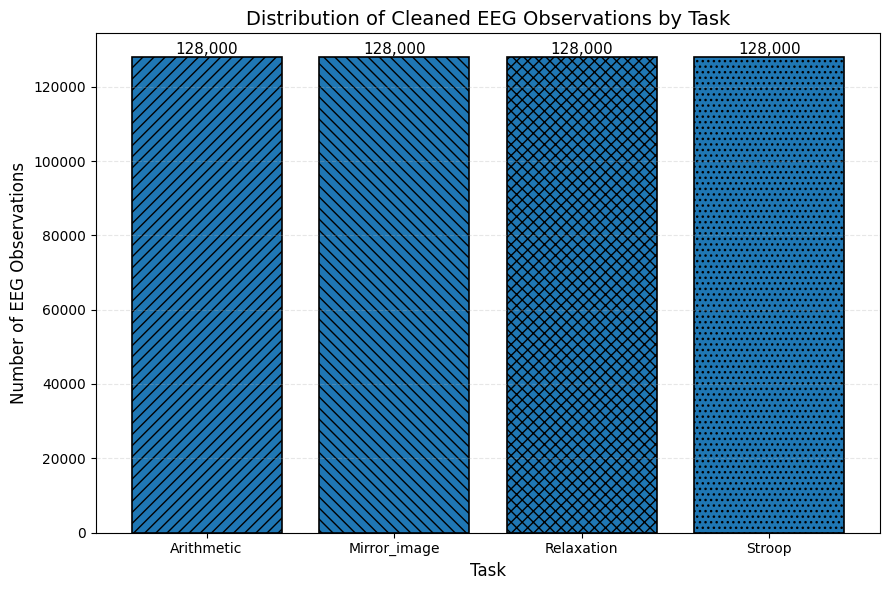

In [17]:
# ============================================================
# 2.13 VISUALIZE CLEANED EEG DATA DISTRIBUTION
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# COUNT OBSERVATIONS BY TASK
# ------------------------------------------------------------

task_counts = (
    cleaned_data['Task']
    .value_counts()
    .sort_index()
)

print("=" * 60)
print("CLEANED EEG DATA DISTRIBUTION BY TASK")
print("=" * 60)

print(task_counts)

# ------------------------------------------------------------
# BAR CHART
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

# Different hatch patterns for each bar
hatches = ['///', '\\\\\\', 'xxx', '...', '+++', '---', 'ooo']

bars = plt.bar(
    task_counts.index.astype(str),
    task_counts.values,
    edgecolor='black',
    linewidth=1.2
)

# Apply different patterns
for bar, hatch in zip(bars, hatches):
    bar.set_hatch(hatch)

# Add values above bars
for bar, value in zip(bars, task_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:,}',
        ha='center',
        va='bottom',
        fontsize=11
    )

plt.xlabel('Task', fontsize=12)
plt.ylabel('Number of EEG Observations', fontsize=12)
plt.title('Distribution of Cleaned EEG Observations by Task', fontsize=14)

plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# 2.13 ICA SUMMARY
# ============================================================

ica_summary_df = pd.DataFrame(
    ica_summary,
    columns=[
        'Subject',
        'Task',
        'Component',
        'ICLabel',
        'Probability',
        'Excluded'
    ]
)

print(
    "ICA summary shape:",
    ica_summary_df.shape
)

display(
    ica_summary_df.head(20)
)

ICA summary shape: (1860, 6)


,Subject,Task,Component,ICLabel,Probability,Excluded
0,1,Arithmetic,0,eye blink,0.789701,False
1,1,Arithmetic,1,heart beat,0.562147,False
2,1,Arithmetic,2,other,0.525084,False
3,1,Arithmetic,3,other,0.920850,False
4,1,Arithmetic,4,other,0.797426,False
5,1,Arithmetic,5,other,0.533999,False
6,1,Arithmetic,6,other,0.643367,False
7,1,Arithmetic,7,other,0.891613,False
8,1,Arithmetic,8,other,0.751625,False
9,1,Arithmetic,9,other,0.702309,False


In [19]:
# ============================================================
# 2.14. NUMBER OF REJECTED COMPONENTS
# ============================================================

removed_summary = (
    ica_summary_df[
        ica_summary_df['Excluded']
    ]
    .groupby(
        [
            'Subject',
            'Task'
        ]
    )
    .size()
    .reset_index(
        name='Components_Removed'
    )
)

display(
    removed_summary
)

,Subject,Task,Components_Removed
0,1,Stroop,1
1,2,Stroop,1
2,3,Relaxation,1
3,4,Mirror_image,1
4,6,Arithmetic,1
5,6,Stroop,1
6,9,Mirror_image,1
7,11,Relaxation,1
8,17,Mirror_image,1
9,21,Relaxation,1


In [20]:
# ============================================================
# 2.15 OVERALL ICA SUMMARY
# ============================================================

print(
    "Total ICA components:",
    len(ica_summary_df)
)

print(
    "Total components removed:",
    ica_summary_df[
        'Excluded'
    ].sum()
)

print(
    "Percentage removed:",
    (
        ica_summary_df[
            'Excluded'
        ].mean() * 100
    )
)

Total ICA components: 1860
Total components removed: 12
Percentage removed: 0.6451612903225806


In [21]:
# ============================================================
# 2.16 CHECK FAILED RECORDINGS
# ============================================================

failed_df = pd.DataFrame(
    failed_recordings,
    columns=[
        'Subject',
        'Task',
        'Error'
    ]
)

print(
    "Number of failed recordings:",
    len(failed_df)
)

display(
    failed_df
)

Number of failed recordings: 0


,Subject,Task,Error


### **FEATURE EXTRACTION**

In [22]:
# ============================================================
# PHASE 3 — EEG FEATURE EXTRACTION
#
# INPUT:
#   cleaned_data
#       → EEG after Chebyshev filtering + ICA + ICLabel
#
#   scale_clean
#       → Subject / Trial / Task / Stress_Rating
#
# OUTPUT:
#   feature_wide
#       → 1 row per Subject × Trial × Task
#       → 32 EEG channels
#       → 20 features per channel
#       → 640 EEG features
#
# IMPORTANT:
#   NO CLUSTERING IS PERFORMED IN THIS PHASE.
#
#   The purpose is to create a clean feature representation
#   that will later be diagnosed for:
#       1. Feature redundancy
#       2. Feature informativeness
#       3. Task separability
#       4. Stress-rating association
#       5. Clusterability
# ============================================================

import numpy as np
import pandas as pd

from scipy.signal import welch
from scipy.stats import skew, kurtosis


# ============================================================
# 3.1 PARAMETERS
# ============================================================

FS = 128

# EEG frequency bands
BANDS = {
    'Delta': (0.5, 4),
    'Theta': (4, 8),
    'Alpha': (8, 12),
    'Beta':  (12, 30),
    'Gamma': (30, 43)
}

# Expected number of EEG features
EXPECTED_FEATURES_PER_CHANNEL = 20
EXPECTED_TOTAL_FEATURES = len(channels) * EXPECTED_FEATURES_PER_CHANNEL

print("=" * 70)
print("PHASE 2 — EEG FEATURE EXTRACTION")
print("=" * 70)

print(f"Sampling frequency       : {FS} Hz")
print(f"Number of channels       : {len(channels)}")
print(f"Features per channel     : {EXPECTED_FEATURES_PER_CHANNEL}")
print(f"Expected EEG features    : {EXPECTED_TOTAL_FEATURES}")
print(f"Input cleaned_data shape : {cleaned_data.shape}")


# ============================================================
# 3.2 FEATURE FUNCTIONS
# ============================================================

def spectral_features(signal, fs=128):
    """
    Calculate PSD-based frequency features.

    Returns:
        Delta
        Theta
        Alpha
        Beta
        Gamma
        Spectral Entropy
    """

    signal = np.asarray(signal, dtype=float)

    # Welch PSD
    frequencies, psd = welch(
        signal,
        fs=fs,
        nperseg=min(256, len(signal)),
        noverlap=None
    )

    # Prevent numerical problems
    psd = np.maximum(psd, 0)

    band_power = {}

    for band_name, (low, high) in BANDS.items():

        mask = (
            (frequencies >= low) &
            (frequencies < high)
        )

        if np.any(mask):

            power = np.trapezoid(
                psd[mask],
                frequencies[mask]
            )

        else:
            power = 0.0

        band_power[band_name] = power

    # --------------------------------------------------------
    # Spectral entropy
    # --------------------------------------------------------

    total_power = np.sum(psd)

    if total_power > 0:

        probability = psd / total_power

        spectral_entropy = -np.sum(
            probability *
            np.log2(
                probability + 1e-12
            )
        )

        # Normalize by maximum possible entropy
        if len(probability) > 1:

            spectral_entropy /= np.log2(
                len(probability)
            )

    else:

        spectral_entropy = 0.0

    return (
        band_power['Delta'],
        band_power['Theta'],
        band_power['Alpha'],
        band_power['Beta'],
        band_power['Gamma'],
        spectral_entropy
    )


def hjorth_features(signal):
    """
    Calculate Hjorth Activity, Mobility and Complexity.
    """

    signal = np.asarray(signal, dtype=float)

    # Activity
    activity = np.var(signal)

    # First derivative
    dx = np.diff(signal)

    # Second derivative
    ddx = np.diff(dx)

    var_signal = np.var(signal)
    var_dx = np.var(dx)
    var_ddx = np.var(ddx)

    # Mobility
    if var_signal > 0:

        mobility = np.sqrt(
            var_dx / var_signal
        )

    else:

        mobility = 0.0

    # Complexity
    if var_dx > 0:

        mobility_derivative = np.sqrt(
            var_ddx / var_dx
        )

        if mobility > 0:

            complexity = (
                mobility_derivative /
                mobility
            )

        else:

            complexity = 0.0

    else:

        complexity = 0.0

    return (
        activity,
        mobility,
        complexity
    )


def katz_fd(signal):
    """
    Katz Fractal Dimension.
    """

    signal = np.asarray(signal, dtype=float)

    n = len(signal)

    if n < 2:
        return np.nan

    differences = np.diff(signal)

    total_distance = np.sum(
        np.abs(differences)
    )

    if total_distance <= 0:
        return 1.0

    distances_from_start = np.abs(
        signal - signal[0]
    )

    diameter = np.max(
        distances_from_start
    )

    if diameter <= 0:
        return 1.0

    # Katz formulation
    d = diameter
    L = total_distance

    return (
        np.log10(n) /
        (
            np.log10(n) +
            np.log10(d / L)
        )
    )


def higuchi_fd(signal, kmax=8):
    """
    Higuchi Fractal Dimension.

    A relatively small kmax is used to keep the
    calculation practical for 25-second EEG trials.
    """

    signal = np.asarray(signal, dtype=float)

    n = len(signal)

    if n < 20:
        return np.nan

    L = []

    x = np.arange(n)

    for k in range(1, kmax + 1):

        lengths = []

        for m in range(k):

            indices = np.arange(
                m,
                n,
                k
            )

            if len(indices) < 2:
                continue

            segment = signal[indices]

            length = (
                np.sum(
                    np.abs(
                        np.diff(segment)
                    )
                )
                *
                (n - 1)
                /
                (
                    (len(indices) - 1)
                    * k
                )
            )

            lengths.append(length)

        if len(lengths) > 0:

            L.append(
                np.mean(lengths)
            )

    if len(L) < 2:
        return np.nan

    k_values = np.arange(
        1,
        len(L) + 1
    )

    log_k = np.log(
        1.0 / k_values
    )

    log_L = np.log(
        np.maximum(L, 1e-12)
    )

    slope = np.polyfit(
        log_k,
        log_L,
        1
    )[0]

    return slope


# ============================================================
# 3.3 EXTRACT FEATURES FROM ONE EEG CHANNEL
# ============================================================

def extract_channel_features(
    signal,
    fs=128
):

    signal = np.asarray(
        signal,
        dtype=float
    )

    # --------------------------------------------------------
    # Time-domain features
    # --------------------------------------------------------

    mean_value = np.mean(signal)

    std_value = np.std(
        signal,
        ddof=1
    )

    variance = np.var(
        signal,
        ddof=1
    )

    skewness = skew(
        signal,
        bias=False
    )

    kurt = kurtosis(
        signal,
        fisher=True,
        bias=False
    )

    sum_absolute_difference = np.sum(
        np.abs(
            np.diff(signal)
        )
    )

    peak_to_peak = (
        np.max(signal) -
        np.min(signal)
    )

    signal_energy = np.sum(
        signal ** 2
    )

    # --------------------------------------------------------
    # Frequency-domain features
    # --------------------------------------------------------

    (
        delta_power,
        theta_power,
        alpha_power,
        beta_power,
        gamma_power,
        spectral_entropy
    ) = spectral_features(
        signal,
        fs
    )

    # --------------------------------------------------------
    # Hjorth parameters
    # --------------------------------------------------------

    (
        hjorth_activity,
        hjorth_mobility,
        hjorth_complexity
    ) = hjorth_features(
        signal
    )

    # --------------------------------------------------------
    # Nonlinear features
    # --------------------------------------------------------

    katz = katz_fd(
        signal
    )

    higuchi = higuchi_fd(
        signal
    )

    # --------------------------------------------------------
    # Theta / Beta ratio
    #
    # Small epsilon prevents division by zero.
    # --------------------------------------------------------

    theta_beta_ratio = (
        theta_power /
        (beta_power + 1e-12)
    )

    # --------------------------------------------------------
    # Return exactly 20 features
    # --------------------------------------------------------

    features = {

        'Mean':
            mean_value,

        'Std':
            std_value,

        'Variance':
            variance,

        'Skewness':
            skewness,

        'Kurtosis':
            kurt,

        'SAD':
            sum_absolute_difference,

        'PeakToPeak':
            peak_to_peak,

        'Energy':
            signal_energy,

        'DeltaPower':
            delta_power,

        'ThetaPower':
            theta_power,

        'AlphaPower':
            alpha_power,

        'BetaPower':
            beta_power,

        'GammaPower':
            gamma_power,

        'SpectralEntropy':
            spectral_entropy,

        'HjorthActivity':
            hjorth_activity,

        'HjorthMobility':
            hjorth_mobility,

        'HjorthComplexity':
            hjorth_complexity,

        'KatzFD':
            katz,

        'HiguchiFD':
            higuchi,

        'ThetaBetaRatio':
            theta_beta_ratio
    }

    return features


# ============================================================
# 3.4 FEATURE EXTRACTION FOR ALL RECORDINGS
#
# Each Subject × Trial × Task = ONE observation.
#
# 40 subjects × 4 tasks × 1 trial
# = 160 EEG observations
#
# 32 channels × 20 features
# = 640 EEG features per observation.
# ============================================================

feature_rows = []

failed_features = []


recording_groups = cleaned_data.groupby(
    ['Subject', 'Trial', 'Task'],
    sort=True
)


print("\n")
print("=" * 70)
print("EXTRACTING EEG FEATURES")
print("=" * 70)

print(
    f"Number of recordings: "
    f"{len(recording_groups)}"
)


for recording_index, (
    (subject, trial, task),
    group
) in enumerate(
    recording_groups,
    start=1
):

    print(
        f"[{recording_index:03d}/"
        f"{len(recording_groups):03d}] "
        f"Subject {subject:02d} | "
        f"Trial {trial} | "
        f"{task}"
    )

    try:

        group = group.sort_values(
            'Sample'
        )

        # ----------------------------------------------------
        # Verify recording dimensions
        # ----------------------------------------------------

        if len(group) != 3200:

            raise ValueError(
                f"Expected 3200 samples, "
                f"found {len(group)}"
            )

        if not all(
            channel in group.columns
            for channel in channels
        ):

            raise ValueError(
                "Missing EEG channel"
            )

        # ----------------------------------------------------
        # Metadata
        # ----------------------------------------------------

        row = {

            'Subject':
                subject,

            'Trial':
                trial,

            'Task':
                task
        }

        # ----------------------------------------------------
        # Extract 20 features from each
        # of the 32 EEG channels.
        # ----------------------------------------------------

        for channel in channels:

            signal = group[
                channel
            ].values

            channel_features = (
                extract_channel_features(
                    signal,
                    fs=FS
                )
            )

            for feature_name, value in (
                channel_features.items()
            ):

                column_name = (
                    f'{channel}_{feature_name}'
                )

                row[column_name] = value

        feature_rows.append(
            row
        )

    except Exception as e:

        print(
            f"  ERROR: {e}"
        )

        failed_features.append([
            subject,
            trial,
            task,
            str(e)
        ])


# ============================================================
# 3.5 CREATE FEATURE TABLE
# ============================================================

feature_wide = pd.DataFrame(
    feature_rows
)


print("\n")
print("=" * 70)
print("FEATURE EXTRACTION COMPLETE")
print("=" * 70)

print(
    "Feature table shape:",
    feature_wide.shape
)

print(
    "Number of recordings:",
    len(feature_wide)
)

print(
    "Number of EEG feature columns:",
    len(
        [
            c for c in feature_wide.columns
            if c not in [
                'Subject',
                'Trial',
                'Task'
            ]
        ]
    )
)


# ============================================================
# 3.6 MERGE STRESS RATINGS
#
# IMPORTANT:
# Relaxation remains NaN.
#
# We DO NOT assign Relaxation = 0.
# ============================================================

feature_wide = feature_wide.merge(
    scale_clean[
        [
            'Subject',
            'Trial',
            'Task',
            'Stress_Rating'
        ]
    ],
    on=[
        'Subject',
        'Trial',
        'Task'
    ],
    how='left'
)


# ============================================================
# 3.7 VERIFY STRESS RATINGS
# ============================================================

print("\n")
print("=" * 70)
print("STRESS-RATING VERIFICATION")
print("=" * 70)

rating_check = (
    feature_wide
    .groupby('Task')
    .agg(
        Rated=('Stress_Rating', 'count'),
        Total=('Stress_Rating', 'size')
    )
)

rating_check['Missing'] = (
    rating_check['Total']
    - rating_check['Rated']
)

display(rating_check)


# ------------------------------------------------------------
# Check rating range for rated tasks only
# ------------------------------------------------------------

rated_data = feature_wide[
    feature_wide['Stress_Rating'].notna()
]

print("\nStress-rating range:")

print(
    "Minimum:",
    rated_data['Stress_Rating'].min()
)

print(
    "Maximum:",
    rated_data['Stress_Rating'].max()
)


# ------------------------------------------------------------
# Check each task separately
# ------------------------------------------------------------

print("\nStress-rating statistics by task:")

display(
    rated_data
    .groupby('Task')['Stress_Rating']
    .agg([
        'count',
        'mean',
        'std',
        'min',
        'median',
        'max'
    ])
)


# ------------------------------------------------------------
# Explicitly verify Relaxation
# ------------------------------------------------------------

relaxation_ratings = feature_wide.loc[
    feature_wide['Task'] == 'Relaxation',
    'Stress_Rating'
]

print("\nRelaxation stress ratings:")

print(
    relaxation_ratings.unique()
)

if relaxation_ratings.isna().all():

    print(
        "✓ Correct: Relaxation has no "
        "observed Stress_Rating."
    )

else:

    print(
        "WARNING: Relaxation contains "
        "Stress_Rating values."
    )


# ============================================================
# 3.8 VERIFY EEG FEATURE COUNT
# ============================================================

metadata_columns = [
    'Subject',
    'Trial',
    'Task',
    'Stress_Rating'
]

eeg_feature_columns = [
    c for c in feature_wide.columns
    if c not in metadata_columns
]


print("\n")
print("=" * 70)
print("FEATURE MATRIX VALIDATION")
print("=" * 70)

print(
    "Expected EEG features:",
    EXPECTED_TOTAL_FEATURES
)

print(
    "Actual EEG features:",
    len(eeg_feature_columns)
)

print(
    "Feature matrix:",
    feature_wide[
        eeg_feature_columns
    ].shape
)


if len(eeg_feature_columns) == EXPECTED_TOTAL_FEATURES:

    print(
        "✓ Correct: "
        "32 channels × 20 features = 640"
    )

else:

    print(
        "WARNING: Feature count does not "
        "match expected 640."
    )


# ============================================================
# 3.9 CHECK MISSING / INVALID VALUES
# ============================================================

X_features = feature_wide[
    eeg_feature_columns
].copy()


missing_count = (
    X_features.isna()
    .sum()
    .sum()
)

infinite_count = np.isinf(
    X_features.values
).sum()


print("\n")
print("=" * 70)
print("FEATURE QUALITY CHECK")
print("=" * 70)

print(
    "Missing feature values:",
    missing_count
)

print(
    "Infinite feature values:",
    infinite_count
)


# ------------------------------------------------------------
# Replace infinite values with NaN
# ------------------------------------------------------------

X_features = X_features.replace(
    [np.inf, -np.inf],
    np.nan
)


# ------------------------------------------------------------
# Report problematic features
# ------------------------------------------------------------

problematic_features = (
    X_features.columns[
        X_features.isna().any()
    ]
    .tolist()
)


print(
    "Features containing NaN:",
    len(problematic_features)
)

if len(problematic_features) > 0:

    print(
        problematic_features[:20]
    )


# ============================================================
# 3.10 CHECK CONSTANT / NEAR-CONSTANT FEATURES
# ============================================================

feature_variance = (
    X_features.var(
        axis=0,
        skipna=True
    )
)

constant_features = (
    feature_variance[
        feature_variance == 0
    ]
    .index
    .tolist()
)

near_constant_features = (
    feature_variance[
        feature_variance < 1e-12
    ]
    .index
    .tolist()
)


print("\n")
print("=" * 70)
print("VARIANCE CHECK")
print("=" * 70)

print(
    "Constant features:",
    len(constant_features)
)

print(
    "Near-constant features:",
    len(near_constant_features)
)


# ============================================================
# 3.11 BASIC FEATURE SUMMARY
# ============================================================

feature_summary = pd.DataFrame({

    'Missing':
        X_features.isna().sum(),

    'Variance':
        X_features.var(
            skipna=True
        ),

    'Mean':
        X_features.mean(
            skipna=True
        ),

    'Std':
        X_features.std(
            skipna=True
        ),

    'Min':
        X_features.min(
            skipna=True
        ),

    'Max':
        X_features.max(
            skipna=True
        )
})


display(
    feature_summary.head(20)
)


# ============================================================
# 3.12 STANDARDIZE FEATURES
#
# IMPORTANT:
# This standardized matrix is for later analysis.
#
# We retain BOTH:
#
#   feature_wide
#       → original feature values
#
#   X_scaled
#       → standardized feature values
#
# Do not overwrite the original features.
# ============================================================

# ------------------------------------------------------------
# Temporarily fill missing values using feature median
# ONLY if necessary.
# ------------------------------------------------------------

if X_features.isna().sum().sum() > 0:

    X_for_scaling = (
        X_features
        .fillna(
            X_features.median()
        )
    )

else:

    X_for_scaling = X_features.copy()


scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    X_for_scaling
)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=eeg_feature_columns,
    index=feature_wide.index
)


print("\n")
print("=" * 70)
print("STANDARDIZED FEATURE MATRIX")
print("=" * 70)

print(
    "Shape:",
    X_scaled.shape
)

print(
    "Mean:",
    X_scaled.mean().mean()
)

print(
    "Average SD:",
    X_scaled.std().mean()
)


# ============================================================
# 3.13 FINAL DATASET
# ============================================================

# Keep metadata + original EEG features + rating.
#
# X_scaled is kept separately because later diagnostics
# may require standardized values.

feature_dataset = feature_wide[
    metadata_columns +
    eeg_feature_columns
].copy()


print("\n")
print("=" * 70)
print("FINAL FEATURE DATASET")
print("=" * 70)

print(
    feature_dataset.shape
)

display(
    feature_dataset.head()
)


# ============================================================
# 3.14 SAVE FEATURE DATA
# ============================================================

feature_output_path = (
    '/content/drive/MyDrive/Journal/'
    'SAM40_trial1_EEG_features_640.csv'
)

feature_dataset.to_csv(
    feature_output_path,
    index=False
)


# Save standardized matrix separately
scaled_output_path = (
    '/content/drive/MyDrive/Journal/'
    'SAM40_trial1_EEG_features_640_scaled.csv'
)

scaled_dataset = pd.concat(
    [
        feature_wide[
            metadata_columns
        ].reset_index(drop=True),

        X_scaled.reset_index(drop=True)
    ],
    axis=1
)

scaled_dataset.to_csv(
    scaled_output_path,
    index=False
)


# ============================================================
# 3.15 FAILED RECORDINGS
# ============================================================

failed_features_df = pd.DataFrame(
    failed_features,
    columns=[
        'Subject',
        'Trial',
        'Task',
        'Error'
    ]
)

print("\n")
print("=" * 70)
print("FAILED FEATURE EXTRACTIONS")
print("=" * 70)

print(
    "Number of failed recordings:",
    len(failed_features_df)
)

if len(failed_features_df) > 0:

    display(
        failed_features_df
    )


# ============================================================
# 3.16 FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 70)
print("PHASE 2 SUMMARY")
print("=" * 70)

print(
    f"Recordings extracted : {len(feature_dataset)}"
)

print(
    f"EEG channels          : {len(channels)}"
)

print(
    f"Features/channel      : "
    f"{EXPECTED_FEATURES_PER_CHANNEL}"
)

print(
    f"Total EEG features    : "
    f"{len(eeg_feature_columns)}"
)

print(
    f"Feature matrix        : "
    f"{X_scaled.shape}"
)

print(
    f"Stress-rated rows     : "
    f"{feature_dataset['Stress_Rating'].notna().sum()}"
)

print(
    f"Unrated rows          : "
    f"{feature_dataset['Stress_Rating'].isna().sum()}"
)

print(
    f"Failed recordings     : "
    f"{len(failed_features_df)}"
)

print("\nTasks:")

print(
    feature_dataset['Task']
    .value_counts()
)

print("\nSaved:")

print(
    feature_output_path
)

print(
    scaled_output_path
)

PHASE 2 — EEG FEATURE EXTRACTION
Sampling frequency       : 128 Hz
Number of channels       : 32
Features per channel     : 20
Expected EEG features    : 640
Input cleaned_data shape : (512000, 37)


EXTRACTING EEG FEATURES
Number of recordings: 160
[001/160] Subject 01 | Trial 1 | Arithmetic
[002/160] Subject 01 | Trial 1 | Mirror_image
[003/160] Subject 01 | Trial 1 | Relaxation
[004/160] Subject 01 | Trial 1 | Stroop
[005/160] Subject 02 | Trial 1 | Arithmetic
[006/160] Subject 02 | Trial 1 | Mirror_image
[007/160] Subject 02 | Trial 1 | Relaxation
[008/160] Subject 02 | Trial 1 | Stroop
[009/160] Subject 03 | Trial 1 | Arithmetic
[010/160] Subject 03 | Trial 1 | Mirror_image
[011/160] Subject 03 | Trial 1 | Relaxation
[012/160] Subject 03 | Trial 1 | Stroop
[013/160] Subject 04 | Trial 1 | Arithmetic
[014/160] Subject 04 | Trial 1 | Mirror_image
[015/160] Subject 04 | Trial 1 | Relaxation
[016/160] Subject 04 | Trial 1 | Stroop
[017/160] Subject 05 | Trial 1 | Arithmetic
[018/160] 

,Rated,Total,Missing
Task,,,
Arithmetic,40,40,0
Mirror_image,40,40,0
Relaxation,0,40,40
Stroop,40,40,0



Stress-rating range:
Minimum: 1.0
Maximum: 10.0

Stress-rating statistics by task:


,count,mean,std,min,median,max
Task,,,,,,
Arithmetic,40,5.300,2.065591,2.0,5.0,10.0
Mirror_image,40,5.050,1.947385,1.0,5.0,9.0
Stroop,40,4.125,2.102349,1.0,4.0,9.0



Relaxation stress ratings:
[nan]
✓ Correct: Relaxation has no observed Stress_Rating.


FEATURE MATRIX VALIDATION
Expected EEG features: 640
Actual EEG features: 640
Feature matrix: (160, 640)
✓ Correct: 32 channels × 20 features = 640


FEATURE QUALITY CHECK
Missing feature values: 0
Infinite feature values: 0
Features containing NaN: 0


VARIANCE CHECK
Constant features: 0
Near-constant features: 0


,Missing,Variance,Mean,Std,Min,Max
Cz_Mean,0,2.880122e-02,0.009908,0.169709,-0.485866,8.755649e-01
Cz_Std,0,3.423242e+01,15.540221,5.850848,9.482301,5.251809e+01
Cz_Variance,0,8.129214e+04,275.516924,285.117759,89.914026,2.758150e+03
Cz_Skewness,0,4.437912e-02,0.042545,0.210664,-1.012212,7.881874e-01
Cz_Kurtosis,0,3.865581e+00,0.778298,1.966108,-0.324643,1.869830e+01
Cz_SAD,0,3.373631e+07,20212.403578,5808.296710,11834.567476,3.934075e+04
Cz_PeakToPeak,0,4.851430e+03,122.859723,69.652208,65.940568,6.559404e+02
Cz_Energy,0,8.320894e+11,881470.541966,912189.364754,287648.989018,8.823543e+06
Cz_DeltaPower,0,4.827507e+04,150.082320,219.715895,38.103027,2.187628e+03
Cz_ThetaPower,0,1.933701e+02,26.923494,13.905759,8.928271,1.505049e+02




STANDARDIZED FEATURE MATRIX
Shape: (160, 640)
Mean: -9.852145141375776e-18
Average SD: 1.0031397251510383


FINAL FEATURE DATASET
(160, 644)


,Subject,Trial,Task,Stress_Rating,Cz_Mean,Cz_Std,Cz_Variance,Cz_Skewness,Cz_Kurtosis,Cz_SAD,...,Fp2_AlphaPower,Fp2_BetaPower,Fp2_GammaPower,Fp2_SpectralEntropy,Fp2_HjorthActivity,Fp2_HjorthMobility,Fp2_HjorthComplexity,Fp2_KatzFD,Fp2_HiguchiFD,Fp2_ThetaBetaRatio
0,1,1,Arithmetic,6.0,-0.092056,11.984947,143.638967,0.071462,0.496034,16236.688035,...,37.882910,29.273020,13.111695,0.503415,2256.242001,0.199078,5.406667,2.100373,0.497445,8.430005
1,1,1,Mirror_image,3.0,-0.022798,13.955967,194.769027,0.293913,0.754448,16353.394554,...,32.473976,31.046623,12.313238,0.485167,2315.437174,0.202012,5.111821,2.137111,0.468553,6.922135
2,1,1,Relaxation,NaN,0.014199,27.362734,748.719222,0.047673,4.313114,18455.369727,...,67.930956,31.058036,15.597366,0.494397,6370.127993,0.166319,5.118183,2.267060,0.280945,23.793253
3,1,1,Stroop,3.0,-0.233862,12.618703,159.231667,0.285160,0.288769,17438.046744,...,33.365213,25.094500,11.278316,0.504115,2249.416902,0.196062,5.204881,2.087167,0.496500,10.373359
4,2,1,Arithmetic,3.0,0.151086,11.149410,124.309340,0.174727,-0.004206,13924.684402,...,15.236536,20.823401,9.053350,0.553750,837.972655,0.257381,4.490071,2.176560,0.583226,3.181643




FAILED FEATURE EXTRACTIONS
Number of failed recordings: 0


PHASE 2 SUMMARY
Recordings extracted : 160
EEG channels          : 32
Features/channel      : 20
Total EEG features    : 640
Feature matrix        : (160, 640)
Stress-rated rows     : 120
Unrated rows          : 40
Failed recordings     : 0

Tasks:
Task
Arithmetic      40
Mirror_image    40
Relaxation      40
Stroop          40
Name: count, dtype: int64

Saved:
/content/drive/MyDrive/Journal/SAM40_trial1_EEG_features_640.csv
/content/drive/MyDrive/Journal/SAM40_trial1_EEG_features_640_scaled.csv


### **CLUSTERING**

In [23]:
# ============================================================
# PHASE 9 — EEG-DERIVED STRESS PATTERN DISCOVERY
#
# PURPOSE
# ------------------------------------------------------------
# Discover EEG-derived stress states WITHOUT using
# Stress_Rating as a clustering target.
#
# IMPORTANT METHODOLOGICAL DESIGN
# ------------------------------------------------------------
#
# Relaxation is NOT clustered.
#
# Relaxation is used as a subject-specific EEG baseline.
#
# For every stress observation:
#
#     EEG deviation =
#         Stress-task EEG
#         -
#         Subject-specific Relaxation EEG baseline
#
# CHAMELEON clustering is then performed ONLY on the
# 120 stress-task observations.
#
# DISTANCE:
#
#     Pearson correlation distance
#
#         d(i,j) = 1 - PearsonCorrelation(i,j)
#
# NO EUCLIDEAN DISTANCE IS USED.
#
# Stress_Rating:
#
#     NOT used during clustering.
#
# It is used only AFTER clustering for external
# interpretation/ordering of the discovered states.
#
# OUTPUT:
#
#     K = 2
#     K = 3
#     K = 4
#
# ============================================================


# ============================================================
# 9.1 IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency
from scipy.stats import kruskal

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score
)

from sklearn.manifold import MDS

import warnings

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)


# ============================================================
# 9.2 PARAMETERS
# ============================================================

KNN_K = 10

INITIAL_SUBCLUSTERS = 20

CHAMELEON_ALPHA = 1.0

TARGET_K_VALUES = [2, 3, 4]

STABILITY_REPEATS = 10

STABILITY_SAMPLE_FRACTION = 0.80


# ============================================================
# 9.3 IDENTIFY EEG FEATURES
# ============================================================

metadata_columns = [
    'Subject',
    'Trial',
    'Task',
    'Stress_Rating'
]

eeg_feature_columns = [
    c for c in feature_dataset.columns
    if c not in metadata_columns
]

print("=" * 75)
print("PHASE 9 — EEG-DERIVED STRESS PATTERN DISCOVERY")
print("=" * 75)

print(
    "Feature dataset shape:",
    feature_dataset.shape
)

print(
    "EEG features:",
    len(eeg_feature_columns)
)

if len(eeg_feature_columns) != 640:

    raise ValueError(
        f"Expected 640 EEG features, "
        f"but found {len(eeg_feature_columns)}."
    )

print("✓ All 640 EEG features found.")


# ============================================================
# 9.4 CHECK TASK STRUCTURE
# ============================================================

print("\n")
print("-" * 75)
print("TASK DISTRIBUTION")
print("-" * 75)

print(
    feature_dataset['Task'].value_counts()
)


# ============================================================
# 9.5 DEFINE STRESS AND RELAXATION DATA
# ============================================================

stress_tasks = [
    'Arithmetic',
    'Mirror_image',
    'Stroop'
]

relaxation_task = 'Relaxation'


stress_df = feature_dataset[
    feature_dataset['Task'].isin(
        stress_tasks
    )
].copy()


relaxation_df = feature_dataset[
    feature_dataset['Task'] ==
    relaxation_task
].copy()


print("\n")
print("-" * 75)
print("CLUSTERING DATA")
print("-" * 75)

print(
    "Stress observations:",
    len(stress_df)
)

print(
    "Relaxation observations:",
    len(relaxation_df)
)

print(
    "Relaxation included in clustering:",
    "NO"
)


# ============================================================
# 9.6 PREPARE EEG FEATURE MATRIX
# ============================================================

all_features = feature_dataset[
    eeg_feature_columns
].copy()

all_features = all_features.replace(
    [np.inf, -np.inf],
    np.nan
)

all_features = all_features.fillna(
    all_features.median()
)

feature_dataset_clean = feature_dataset.copy()

feature_dataset_clean[
    eeg_feature_columns
] = all_features


stress_df = feature_dataset_clean[
    feature_dataset_clean['Task'].isin(
        stress_tasks
    )
].copy()


relaxation_df = feature_dataset_clean[
    feature_dataset_clean['Task'] ==
    relaxation_task
].copy()


# ============================================================
# 9.7 SUBJECT-SPECIFIC RELAXATION BASELINE
# ============================================================

print("\n")
print("=" * 75)
print("SUBJECT-SPECIFIC RELAXATION BASELINE")
print("=" * 75)

baseline_by_subject = (
    relaxation_df
    .groupby('Subject')[
        eeg_feature_columns
    ]
    .mean()
)


print(
    "Baseline matrix:",
    baseline_by_subject.shape
)

print(
    "Subjects with relaxation:",
    baseline_by_subject.shape[0]
)


# ============================================================
# 9.8 CALCULATE STRESS DEVIATION FROM RELAXATION
# ============================================================
#
# For each stress observation:
#
#     deviation =
#         stress EEG
#         -
#         subject relaxation baseline
#
# This produces an EEG representation of how much the
# stress-task EEG differs from the individual's relaxed state.
#
# ============================================================

deviation_rows = []

valid_indices = []

for idx, row in stress_df.iterrows():

    subject = row['Subject']

    if subject not in baseline_by_subject.index:

        continue

    stress_values = (
        row[eeg_feature_columns]
        .astype(float)
        .values
    )

    baseline_values = (
        baseline_by_subject
        .loc[
            subject,
            eeg_feature_columns
        ]
        .astype(float)
        .values
    )

    deviation = (
        stress_values -
        baseline_values
    )

    deviation_rows.append(
        deviation
    )

    valid_indices.append(idx)


if len(deviation_rows) == 0:

    raise ValueError(
        "No stress observations have "
        "a matching Relaxation baseline."
    )


X_deviation = np.vstack(
    deviation_rows
)


stress_cluster_df = stress_df.loc[
    valid_indices
].copy()

stress_cluster_df.reset_index(
    drop=True,
    inplace=True
)


print(
    "\nStress observations with baseline:",
    len(stress_cluster_df)
)

print(
    "Deviation matrix:",
    X_deviation.shape
)


# ============================================================
# 9.9 STANDARDISE DEVIATION FEATURES
# ============================================================
#
# Standardisation is performed across observations.
#
# Pearson correlation remains the clustering distance.
#
# No Euclidean distance is calculated.
#
# ============================================================

X_deviation = np.nan_to_num(
    X_deviation,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

scaler_cluster = StandardScaler()

X_cluster = scaler_cluster.fit_transform(
    X_deviation
)

X_cluster = np.asarray(
    X_cluster,
    dtype=float
)


print(
    "Standardised clustering matrix:",
    X_cluster.shape
)


# ============================================================
# 9.10 PEARSON CORRELATION DISTANCE
# ============================================================

print("\n")
print("=" * 75)
print("PEARSON CORRELATION DISTANCE")
print("=" * 75)

correlation_matrix = np.corrcoef(
    X_cluster
)

correlation_matrix = np.nan_to_num(
    correlation_matrix,
    nan=0.0,
    posinf=1.0,
    neginf=-1.0
)

distance_matrix = (
    1.0 -
    correlation_matrix
)

distance_matrix = np.clip(
    distance_matrix,
    0.0,
    2.0
)

np.fill_diagonal(
    distance_matrix,
    0.0
)

upper = distance_matrix[
    np.triu_indices_from(
        distance_matrix,
        k=1
    )
]

print(
    "Distance matrix:",
    distance_matrix.shape
)

print(
    "Minimum distance:",
    upper.min()
)

print(
    "Maximum distance:",
    upper.max()
)

print(
    "Distance used:",
    "1 - Pearson correlation"
)

print(
    "Euclidean distance:",
    "NOT USED"
)


# ============================================================
# 9.11 BUILD WEIGHTED KNN GRAPH
# ============================================================

def build_chameleon_graph(
    distance_matrix,
    knn_k=10
):

    n = distance_matrix.shape[0]

    G = nx.Graph()

    G.add_nodes_from(
        range(n)
    )

    for i in range(n):

        distances = distance_matrix[i].copy()

        distances[i] = np.inf

        nearest = np.argsort(
            distances
        )[:knn_k]

        for j in nearest:

            d = distances[j]

            weight = (
                1.0 /
                (1.0 + d)
            )

            if G.has_edge(i, j):

                if weight > G[i][j]['weight']:

                    G[i][j]['weight'] = weight

            else:

                G.add_edge(
                    i,
                    j,
                    weight=weight
                )

    return G


G = build_chameleon_graph(
    distance_matrix,
    KNN_K
)


print("\n")
print("-" * 75)
print("CHAMELEON KNN GRAPH")
print("-" * 75)

print(
    "Nodes:",
    G.number_of_nodes()
)

print(
    "Edges:",
    G.number_of_edges()
)

print(
    "Connected components:",
    nx.number_connected_components(G)
)


# ============================================================
# 9.12 GRAPH PARTITIONING
# ============================================================

def recursive_graph_partition(
    G,
    target_partitions,
    seed=42
):

    rng = np.random.default_rng(
        seed
    )

    partitions = [
        list(G.nodes())
    ]

    while len(partitions) < target_partitions:

        sizes = [
            len(p)
            for p in partitions
        ]

        split_index = int(
            np.argmax(sizes)
        )

        current = partitions.pop(
            split_index
        )

        if len(current) < 4:

            partitions.append(
                current
            )

            splittable = [
                i
                for i, p
                in enumerate(partitions)
                if len(p) >= 4
            ]

            if not splittable:

                break

            current = partitions.pop(
                splittable[0]
            )

        subgraph = G.subgraph(
            current
        ).copy()

        try:

            A, B = nx.community.kernighan_lin_bisection(
                subgraph,
                weight='weight',
                seed=int(
                    rng.integers(
                        0,
                        1_000_000
                    )
                )
            )

            A = list(A)
            B = list(B)

            if len(A) == 0 or len(B) == 0:

                partitions.append(
                    current
                )

                break

            partitions.append(A)
            partitions.append(B)

        except Exception:

            shuffled = current.copy()

            rng.shuffle(
                shuffled
            )

            midpoint = len(shuffled) // 2

            partitions.append(
                shuffled[:midpoint]
            )

            partitions.append(
                shuffled[midpoint:]
            )

    return partitions


initial_partitions = recursive_graph_partition(
    G,
    INITIAL_SUBCLUSTERS,
    seed=SEED
)


print("\n")
print("-" * 75)
print("INITIAL FINE-GRAIN PARTITION")
print("-" * 75)

print(
    "Requested:",
    INITIAL_SUBCLUSTERS
)

print(
    "Obtained:",
    len(initial_partitions)
)

print(
    "Sizes:",
    [
        len(p)
        for p in initial_partitions
    ]
)


# ============================================================
# 9.13 CHAMELEON CONNECTIVITY FUNCTIONS
# ============================================================

def internal_interconnectivity(
    G,
    nodes
):

    nodes = list(nodes)

    if len(nodes) < 4:

        subgraph = G.subgraph(
            nodes
        )

        total = sum(
            data['weight']
            for _, _, data
            in subgraph.edges(
                data=True
            )
        )

        return max(
            total,
            1e-12
        )

    subgraph = G.subgraph(
        nodes
    ).copy()

    try:

        A, B = nx.community.kernighan_lin_bisection(
            subgraph,
            weight='weight',
            seed=SEED
        )

        cut = 0.0

        B = set(B)

        for u in A:

            for v in G.neighbors(u):

                if v in B:

                    cut += (
                        G[u][v]['weight']
                    )

        return max(
            cut,
            1e-12
        )

    except Exception:

        total = sum(
            data['weight']
            for _, _, data
            in subgraph.edges(
                data=True
            )
        )

        return max(
            total,
            1e-12
        )


def absolute_interconnectivity(
    G,
    cluster_a,
    cluster_b
):

    A = set(cluster_a)
    B = set(cluster_b)

    total = 0.0

    for u in A:

        for v in G.neighbors(u):

            if v in B:

                total += (
                    G[u][v]['weight']
                )

    return total


def absolute_closeness(
    G,
    cluster_a,
    cluster_b
):

    A = set(cluster_a)
    B = set(cluster_b)

    weights = []

    for u in A:

        for v in G.neighbors(u):

            if v in B:

                weights.append(
                    G[u][v]['weight']
                )

    if not weights:

        return 0.0

    return np.mean(
        weights
    )


def internal_closeness(
    G,
    nodes
):

    nodes = list(nodes)

    subgraph = G.subgraph(
        nodes
    ).copy()

    if subgraph.number_of_edges() == 0:

        return 1e-12

    if len(nodes) < 4:

        weights = [
            data['weight']
            for _, _, data
            in subgraph.edges(
                data=True
            )
        ]

        return max(
            np.mean(weights),
            1e-12
        )

    try:

        A, B = nx.community.kernighan_lin_bisection(
            subgraph,
            weight='weight',
            seed=SEED
        )

        B = set(B)

        weights = []

        for u in A:

            for v in G.neighbors(u):

                if v in B:

                    weights.append(
                        G[u][v]['weight']
                    )

        if weights:

            return max(
                np.mean(weights),
                1e-12
            )

    except Exception:

        pass

    weights = [
        data['weight']
        for _, _, data
        in subgraph.edges(
            data=True
        )
    ]

    return max(
        np.mean(weights),
        1e-12
    )


def relative_interconnectivity(
    G,
    cluster_a,
    cluster_b
):

    absolute_ic = (
        absolute_interconnectivity(
            G,
            cluster_a,
            cluster_b
        )
    )

    internal_a = (
        internal_interconnectivity(
            G,
            cluster_a
        )
    )

    internal_b = (
        internal_interconnectivity(
            G,
            cluster_b
        )
    )

    denominator = (
        0.5 *
        (
            internal_a +
            internal_b
        )
    )

    if denominator <= 0:

        return 0.0

    return (
        absolute_ic /
        denominator
    )


def relative_closeness(
    G,
    cluster_a,
    cluster_b
):

    absolute_c = (
        absolute_closeness(
            G,
            cluster_a,
            cluster_b
        )
    )

    internal_a = (
        internal_closeness(
            G,
            cluster_a
        )
    )

    internal_b = (
        internal_closeness(
            G,
            cluster_b
        )
    )

    denominator = (
        0.5 *
        (
            internal_a +
            internal_b
        )
    )

    if denominator <= 0:

        return 0.0

    return (
        absolute_c /
        denominator
    )


# ============================================================
# 9.14 CHAMELEON MERGING
# ============================================================

def chameleon_merge(
    G,
    initial_clusters,
    target_k,
    alpha=1.0
):

    clusters = [
        list(c)
        for c in initial_clusters
    ]

    merge_history = []

    while len(clusters) > target_k:

        best_score = -np.inf
        best_pair = None
        best_details = None

        for i in range(
            len(clusters)
        ):

            for j in range(
                i + 1,
                len(clusters)
            ):

                A = clusters[i]
                B = clusters[j]

                inter = (
                    absolute_interconnectivity(
                        G,
                        A,
                        B
                    )
                )

                if inter <= 0:

                    continue

                RI = (
                    relative_interconnectivity(
                        G,
                        A,
                        B
                    )
                )

                RC = (
                    relative_closeness(
                        G,
                        A,
                        B
                    )
                )

                score = (
                    RI *
                    (
                        RC ** alpha
                    )
                )

                if score > best_score:

                    best_score = score
                    best_pair = (i, j)

                    best_details = {
                        'RI': RI,
                        'RC': RC,
                        'Score': score,
                        'Interconnectivity': inter
                    }

        # ----------------------------------------------------
        # fallback if no graph-adjacent pair exists
        # ----------------------------------------------------

        if best_pair is None:

            for i in range(
                len(clusters)
            ):

                for j in range(
                    i + 1,
                    len(clusters)
                ):

                    A = clusters[i]
                    B = clusters[j]

                    RI = (
                        relative_interconnectivity(
                            G,
                            A,
                            B
                        )
                    )

                    RC = (
                        relative_closeness(
                            G,
                            A,
                            B
                        )
                    )

                    score = (
                        RI *
                        (
                            RC ** alpha
                        )
                    )

                    if score > best_score:

                        best_score = score
                        best_pair = (i, j)

                        best_details = {
                            'RI': RI,
                            'RC': RC,
                            'Score': score,
                            'Interconnectivity':
                                absolute_interconnectivity(
                                    G,
                                    A,
                                    B
                                )
                        }

        if best_pair is None:

            raise RuntimeError(
                "No valid CHAMELEON "
                "cluster pair found."
            )

        i, j = best_pair

        merged = (
            clusters[i] +
            clusters[j]
        )

        for index in sorted(
            [i, j],
            reverse=True
        ):

            clusters.pop(
                index
            )

        clusters.append(
            merged
        )

        merge_history.append(
            best_details
        )

    labels = np.empty(
        G.number_of_nodes(),
        dtype=int
    )

    for label, nodes in enumerate(
        clusters
    ):

        for node in nodes:

            labels[node] = label

    return (
        labels,
        clusters,
        merge_history
    )


# ============================================================
# 9.15 RUN CHAMELEON K=2,3,4
# ============================================================

cluster_solutions = {}

print("\n")
print("=" * 75)
print("RUNNING CHAMELEON")
print("=" * 75)

for K in TARGET_K_VALUES:

    print(
        f"\nCHAMELEON K={K}"
    )

    labels, clusters, history = (
        chameleon_merge(
            G,
            initial_partitions,
            target_k=K,
            alpha=CHAMELEON_ALPHA
        )
    )

    cluster_solutions[K] = {
        'labels': labels,
        'clusters': clusters,
        'history': history
    }

    print(
        "Cluster sizes:",
        np.bincount(labels)
    )


# ============================================================
# 9.16 SILHOUETTE
# ============================================================

print("\n")
print("=" * 75)
print("VALIDATION — CORRELATION-DISTANCE SILHOUETTE")
print("=" * 75)

silhouette_results = []

for K in TARGET_K_VALUES:

    labels = (
        cluster_solutions[K]['labels']
    )

    score = silhouette_score(
        distance_matrix,
        labels,
        metric='precomputed'
    )

    silhouette_results.append({
        'K': K,
        'Silhouette': score
    })

    print(
        f"K={K}: {score:.4f}"
    )

silhouette_df = pd.DataFrame(
    silhouette_results
)


# ============================================================
# 9.17 TASK ASSOCIATION
# ============================================================

print("\n")
print("=" * 75)
print("VALIDATION — TASK ASSOCIATION")
print("=" * 75)

task_results = []

for K in TARGET_K_VALUES:

    labels = (
        cluster_solutions[K]['labels']
    )

    temp = pd.DataFrame({
        'Cluster': labels,
        'Task':
            stress_cluster_df[
                'Task'
            ].values
    })

    contingency = pd.crosstab(
        temp['Cluster'],
        temp['Task']
    )

    chi2, p, dof, expected = (
        chi2_contingency(
            contingency
        )
    )

    task_results.append({
        'K': K,
        'ChiSquare': chi2,
        'p_value': p
    })

    print(
        f"\nK={K}"
    )

    print(
        contingency
    )

    print(
        f"Chi-square={chi2:.4f}, "
        f"p={p:.4f}"
    )

task_df = pd.DataFrame(
    task_results
)


# ============================================================
# 9.18 STRESS-RATING EXTERNAL VALIDATION
# ============================================================

print("\n")
print("=" * 75)
print("VALIDATION — STRESS RATING")
print("=" * 75)

stress_results = []

for K in TARGET_K_VALUES:

    labels = (
        cluster_solutions[K]['labels']
    )

    temp = pd.DataFrame({
        'Cluster': labels,
        'Stress_Rating':
            stress_cluster_df[
                'Stress_Rating'
            ].values
    })

    rated = temp[
        temp['Stress_Rating'].notna()
    ]

    groups = []

    for cluster_id in sorted(
        rated['Cluster'].unique()
    ):

        values = rated.loc[
            rated['Cluster'] == cluster_id,
            'Stress_Rating'
        ].values

        if len(values) > 0:

            groups.append(values)

    if len(groups) >= 2:

        H, p = kruskal(
            *groups
        )

    else:

        H = np.nan
        p = np.nan

    stress_results.append({
        'K': K,
        'Kruskal_H': H,
        'p_value': p
    })

    print(
        f"\nK={K}"
    )

    print(
        rated.groupby(
            'Cluster'
        )[
            'Stress_Rating'
        ].agg([
            'count',
            'mean',
            'median',
            'std',
            'min',
            'max'
        ])
    )

    print(
        f"Kruskal-Wallis H={H:.4f}, "
        f"p={p:.4f}"
    )

stress_df_results = pd.DataFrame(
    stress_results
)


# ============================================================
# 9.19 CLUSTER SIZE
# ============================================================

print("\n")
print("=" * 75)
print("VALIDATION — CLUSTER SIZE")
print("=" * 75)

size_results = []

for K in TARGET_K_VALUES:

    labels = (
        cluster_solutions[K]['labels']
    )

    counts = np.bincount(
        labels
    )

    percentages = (
        counts /
        len(labels) *
        100
    )

    size_results.append({
        'K': K,
        'Minimum_n': counts.min(),
        'Maximum_n': counts.max(),
        'Minimum_%': percentages.min(),
        'Maximum_%': percentages.max()
    })

    print(
        f"K={K}:",
        counts,
        np.round(
            percentages,
            2
        )
    )

size_df = pd.DataFrame(
    size_results
)


# ============================================================
# 9.20 SAVE RAW CHAMELEON CLUSTERS
# ============================================================

cluster_output = stress_cluster_df[
    [
        'Subject',
        'Trial',
        'Task',
        'Stress_Rating'
    ]
].copy()

for K in TARGET_K_VALUES:

    cluster_output[
        f'CHAMELEON_K{K}'
    ] = (
        cluster_solutions[K]['labels']
    )


cluster_output_path = (
    '/content/drive/MyDrive/Journal/'
    'SAM40_trial1_CHAMELEON_stress_clusters.csv'
)

cluster_output.to_csv(
    cluster_output_path,
    index=False
)


# ============================================================
# 9.21 SAVE DEVIATION FEATURES
# ============================================================

deviation_feature_df = pd.DataFrame(
    X_deviation,
    columns=eeg_feature_columns
)

deviation_feature_df.insert(
    0,
    'Stress_Rating',
    stress_cluster_df[
        'Stress_Rating'
    ].values
)

deviation_feature_df.insert(
    0,
    'Task',
    stress_cluster_df[
        'Task'
    ].values
)

deviation_feature_df.insert(
    0,
    'Trial',
    stress_cluster_df[
        'Trial'
    ].values
)

deviation_feature_df.insert(
    0,
    'Subject',
    stress_cluster_df[
        'Subject'
    ].values
)


deviation_output_path = (
    '/content/drive/MyDrive/Journal/'
    'SAM40_trial1_stress_baseline_deviation_features.csv'
)

deviation_feature_df.to_csv(
    deviation_output_path,
    index=False
)


print("\n")
print("=" * 75)
print("PHASE 9 COMPLETE")
print("=" * 75)

print(
    "Stress observations clustered:",
    len(stress_cluster_df)
)

print(
    "Relaxation observations:",
    len(relaxation_df)
)

print(
    "Relaxation clustered:",
    "NO"
)

print(
    "EEG features:",
    len(eeg_feature_columns)
)

print(
    "Clustering representation:",
    "Stress EEG - Subject Relaxation baseline"
)

print(
    "Distance:",
    "Pearson correlation distance"
)

print(
    "Euclidean distance:",
    "NOT USED"
)

print(
    "Cluster solutions:",
    TARGET_K_VALUES
)

print("\nSaved:")
print(cluster_output_path)
print(deviation_output_path)

PHASE 9 — EEG-DERIVED STRESS PATTERN DISCOVERY
Feature dataset shape: (160, 644)
EEG features: 640
✓ All 640 EEG features found.


---------------------------------------------------------------------------
TASK DISTRIBUTION
---------------------------------------------------------------------------
Task
Arithmetic      40
Mirror_image    40
Relaxation      40
Stroop          40
Name: count, dtype: int64


---------------------------------------------------------------------------
CLUSTERING DATA
---------------------------------------------------------------------------
Stress observations: 120
Relaxation observations: 40
Relaxation included in clustering: NO


SUBJECT-SPECIFIC RELAXATION BASELINE
Baseline matrix: (40, 640)
Subjects with relaxation: 40

Stress observations with baseline: 120
Deviation matrix: (120, 640)
Standardised clustering matrix: (120, 640)


PEARSON CORRELATION DISTANCE
Distance matrix: (120, 120)
Minimum distance: 0.015055768693902793
Maximum distance: 1.767979

PHASE 9B — COMPREHENSIVE EEG STRESS-STATE VALIDATION
K values: [2, 3, 4]
Observations: 120
EEG features: 640
Representation: Stress EEG - Subject-specific Relaxation baseline
Distance: 1 - Pearson correlation
Stress_Rating: External validation only


9B.4 DATA CHECK
Stress observations: 120
Deviation matrix: (120, 640)
Standardised matrix: (120, 640)
Distance matrix: (120, 120)


9B.5 CLUSTER SIZE VALIDATION

K=2
Cluster counts: [75 45]
Cluster percentages: [62.5 37.5]
Minimum cluster: 45
Adequate: True

K=3
Cluster counts: [15 75 30]
Cluster percentages: [12.5 62.5 25. ]
Minimum cluster: 15
Adequate: True

K=4
Cluster counts: [ 7 15 23 75]
Cluster percentages: [ 5.83 12.5  19.17 62.5 ]
Minimum cluster: 7
Adequate: True


9B.6 CORRELATION-DISTANCE SILHOUETTE
K=2: 0.2629
K=3: 0.2161
K=4: 0.1934


9B.7 TASK ASSOCIATION

K=2
Task     Arithmetic  Mirror_image  Stroop
Cluster                                  
0                24            24      27
1                16            16      1

,K,Feature,Kruskal_H,p_value
235,2,CP1_HjorthMobility,70.369330,4.917860e-17
255,2,P3_HjorthMobility,68.472426,1.286642e-16
256,2,P3_HjorthComplexity,66.601440,3.323433e-16
275,2,P7_HjorthMobility,64.407868,1.011534e-15
236,2,CP1_HjorthComplexity,63.973561,1.261002e-15
315,2,O1_HjorthMobility,63.713682,1.438818e-15
335,2,Pz_HjorthMobility,62.937219,2.134013e-15
355,2,Oz_HjorthMobility,62.679456,2.432397e-15
15,2,Cz_HjorthMobility,62.422222,2.771779e-15
295,2,PO9_HjorthMobility,61.653693,4.094983e-15



Analysing K=3

Top EEG features differentiating K=3 clusters:


,K,Feature,Kruskal_H,p_value
235,3,CP1_HjorthMobility,71.375399,3.169779e-16
315,3,O1_HjorthMobility,70.922094,3.976153e-16
255,3,P3_HjorthMobility,69.876292,6.707427e-16
335,3,Pz_HjorthMobility,68.495383,1.337878e-15
395,3,PO10_HjorthMobility,67.839267,1.857335e-15
256,3,P3_HjorthComplexity,67.535884,2.161569e-15
317,3,O1_KatzFD,67.400479,2.312980e-15
355,3,Oz_HjorthMobility,67.217647,2.534389e-15
313,3,O1_SpectralEntropy,66.857008,3.035185e-15
275,3,P7_HjorthMobility,66.317289,3.975425e-15



Analysing K=4

Top EEG features differentiating K=4 clusters:


...



9B.16 FINAL K COMPARISON


,K,Minimum_Cluster_Size,Maximum_Cluster_Size,Minimum_Percent,Maximum_Percent,Imbalance_Ratio,All_Clusters_>=_Minimum,Silhouette,Task_p_value,Kruskal_H,Stress_Rating_p_value,Significant_EEG_Features_FDR,Stability_Mean_ARI,Stability_STD_ARI,Stability_Min_ARI,Stability_Max_ARI
0,2,45,75,37.500000,62.5,0.600000,True,0.262893,0.726149,1.534881,0.215381,475,0.188653,0.377409,-0.042473,0.958299
1,3,15,75,12.500000,62.5,0.200000,True,0.216150,0.518495,4.989257,0.082527,587,0.403189,0.168333,0.103382,0.763163
2,4,7,75,5.833333,62.5,0.093333,True,0.193350,0.504304,5.510252,0.138027,608,0.760228,0.114272,0.547240,0.885881




9B.17 VALIDITY FLAGS


,K,Adequate_Cluster_Size,Reasonable_Silhouette,Stable,EEG_Differentiation,Stress_Rating_Evidence
0,2,True,True,False,True,False
1,3,True,False,False,True,False
2,4,True,False,True,True,False




9B.18 K RECOMMENDATION
NO K VALUE PASSED ALL CORE VALIDITY CRITERIA.

This is an important result.
It means the current CHAMELEON solutions should NOT yet be treated as definitive stress-state labels.

Do not force K=2, K=3, or K=4.


9B.19 VISUALIZATION


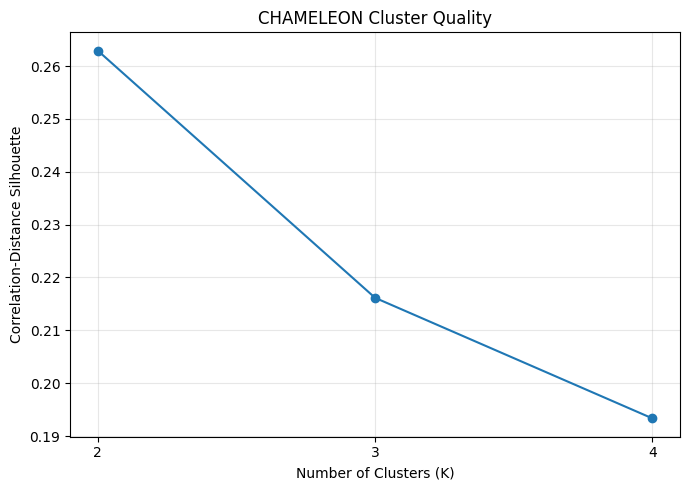

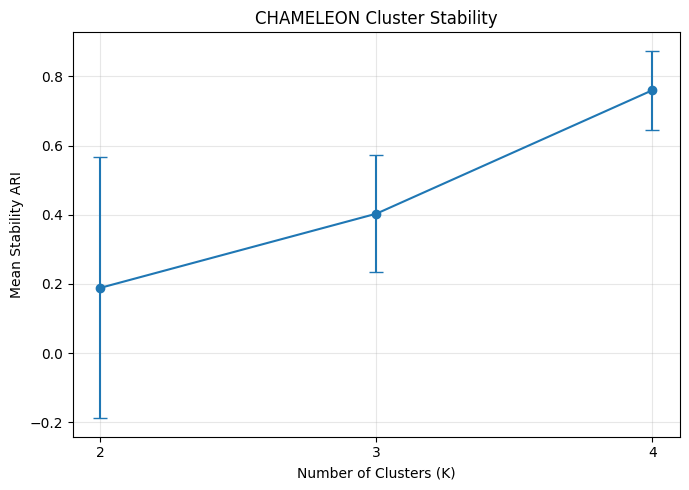

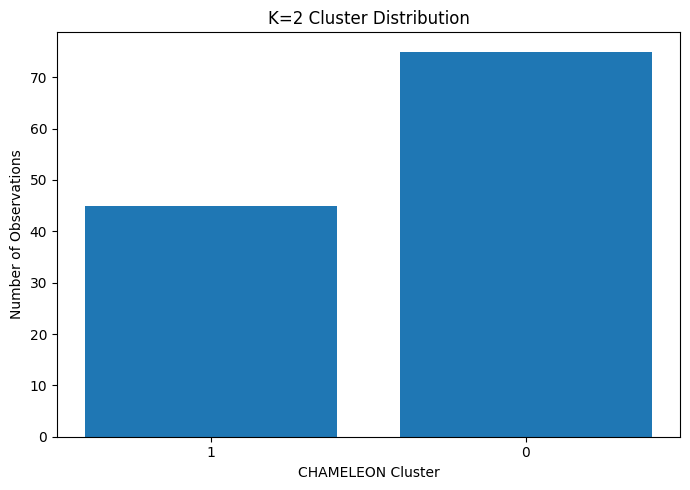

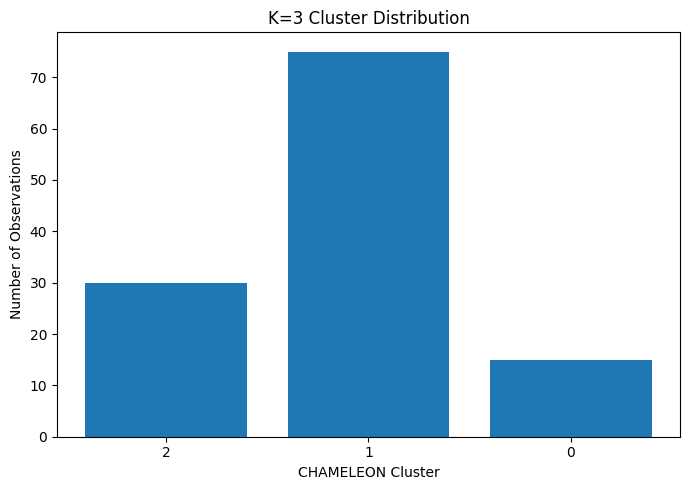

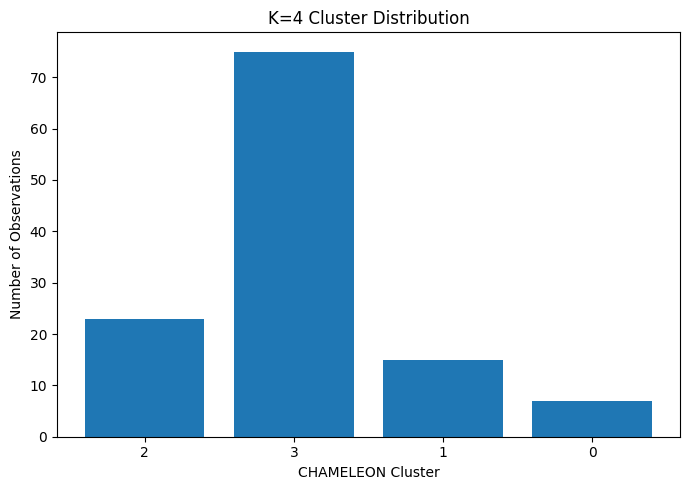

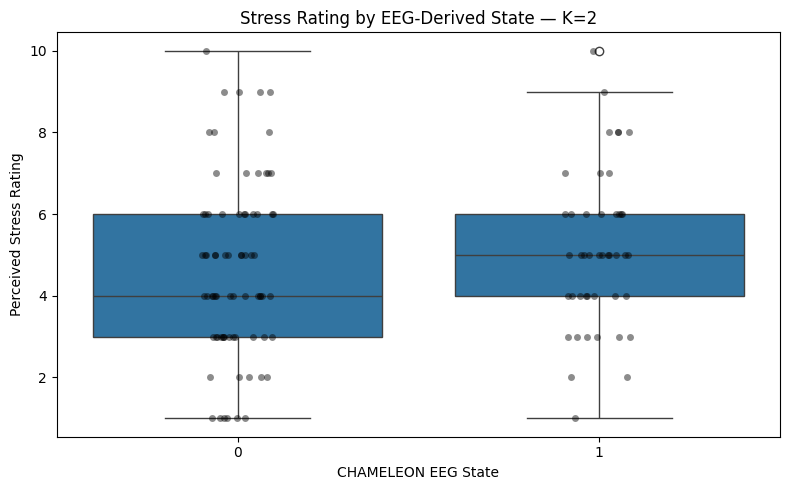

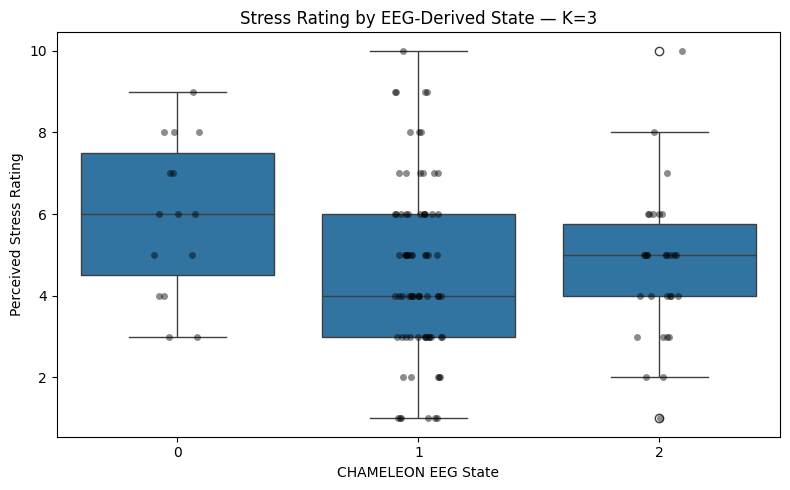

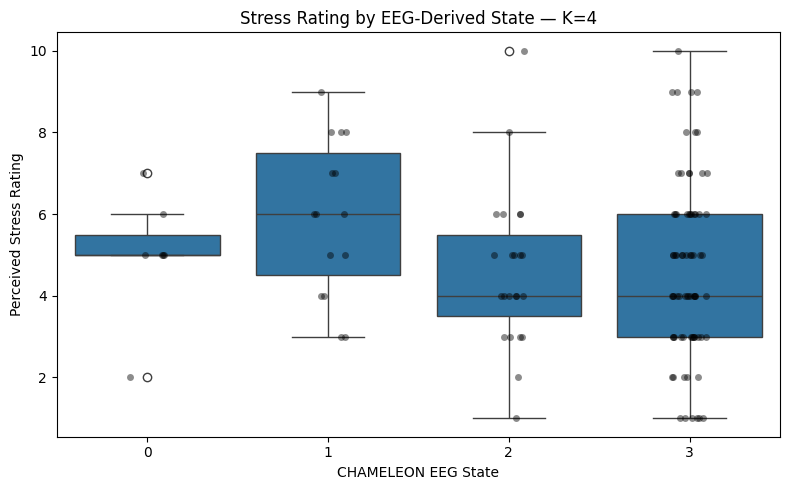

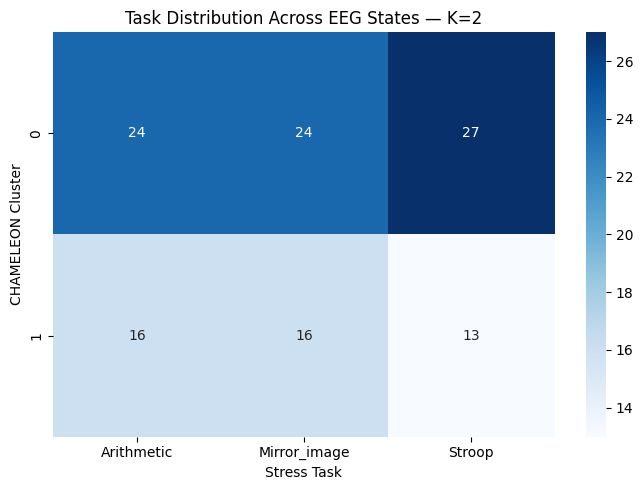

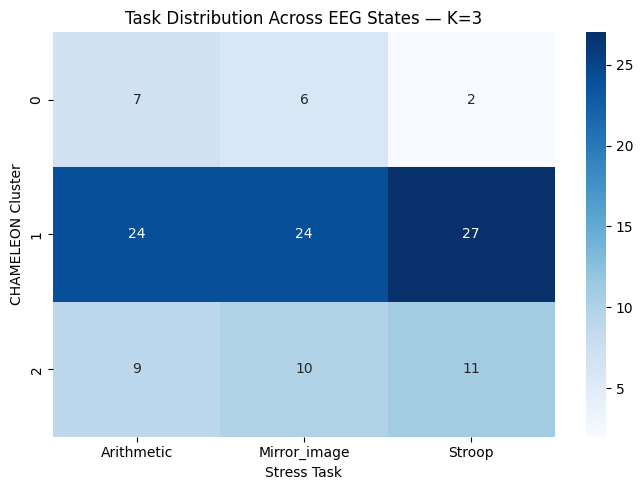

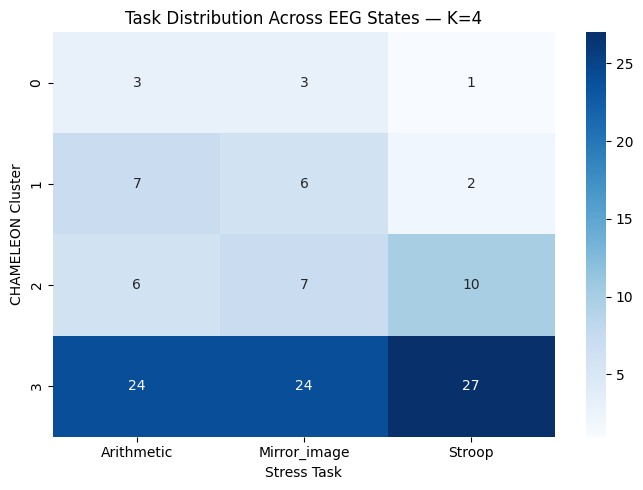



PHASE 9B COMPLETE

K values evaluated: [2, 3, 4]
Minimum cluster size criterion: 5

Core validation:
✓ Cluster size
✓ Correlation-distance silhouette
✓ Task association
✓ Stress_Rating external validation
✓ EEG feature differentiation
✓ FDR correction
✓ Repeated-sampling stability

FINAL RECOMMENDATION:
No K value currently satisfies all core validity criteria.

The clustering should be improved before proceeding to final classification.

Stress_Rating:
Used only as external validation.

Relaxation:
Used only to create subject-specific baseline deviation.

Classification:
NOT performed in Phase 9B.

Saved validation files:
/content/drive/MyDrive/Journal/SAM40_trial1_Phase9B_K_validation.csv
/content/drive/MyDrive/Journal/SAM40_trial1_Phase9B_K_validity_flags.csv
/content/drive/MyDrive/Journal/SAM40_trial1_Phase9B_cluster_stability.csv
/content/drive/MyDrive/Journal/SAM40_trial1_Phase9B_EEG_feature_differentiation.csv


In [24]:
# ============================================================
# PHASE 9B — COMPREHENSIVE EEG STRESS-STATE VALIDATION
#
# PURPOSE
# ------------------------------------------------------------
# Validate the EEG-derived CHAMELEON stress-state solutions
# produced by PHASE 9.
#
# K VALUES:
#     K = 2
#     K = 3
#     K = 4
#
# IMPORTANT:
# ------------------------------------------------------------
# Stress_Rating is NOT used to create clusters.
#
# Stress_Rating is used ONLY as external validation.
#
# Relaxation is NOT clustered.
#
# Phase 9 clustering representation:
#
#     Stress EEG
#         -
#     Subject-specific Relaxation baseline
#
# Distance:
#
#     d = 1 - Pearson correlation
#
# This phase does NOT replace Phase 9.
#
# It validates the cluster solutions produced by Phase 9.
#
# ============================================================


# ============================================================
# 9B.1 IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import (
    kruskal,
    chi2_contingency,
    mannwhitneyu,
    spearmanr
)

from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

from sklearn.preprocessing import StandardScaler

import warnings

warnings.filterwarnings("ignore")


# ============================================================
# 9B.2 PARAMETERS
# ============================================================

SEED = 42

np.random.seed(SEED)

TARGET_K_VALUES = [2, 3, 4]

# ------------------------------------------------------------
# Stability analysis
# ------------------------------------------------------------

STABILITY_REPEATS = 10

STABILITY_SAMPLE_FRACTION = 0.80

# Minimum acceptable cluster size.
#
# This is NOT used to force clustering.
#
# It is only used to identify solutions containing
# extremely small / potentially meaningless clusters.
# ------------------------------------------------------------

MIN_CLUSTER_SIZE = 5

# ------------------------------------------------------------
# Feature ranking
# ------------------------------------------------------------

TOP_FEATURES = 20


# ============================================================
# 9B.3 CHECK PHASE 9 VARIABLES
# ============================================================

required_variables = [
    'stress_cluster_df',
    'X_deviation',
    'X_cluster',
    'distance_matrix',
    'cluster_solutions',
    'eeg_feature_columns'
]

missing_variables = []

for variable in required_variables:

    if variable not in globals():

        missing_variables.append(
            variable
        )


if len(missing_variables) > 0:

    raise RuntimeError(
        "\nPHASE 9B ERROR\n"
        "The following Phase 9 variables are missing:\n"
        f"{missing_variables}\n\n"
        "Please run PHASE 9 first."
    )


print("=" * 75)
print("PHASE 9B — COMPREHENSIVE EEG STRESS-STATE VALIDATION")
print("=" * 75)

print(
    "K values:",
    TARGET_K_VALUES
)

print(
    "Observations:",
    len(stress_cluster_df)
)

print(
    "EEG features:",
    len(eeg_feature_columns)
)

print(
    "Representation:",
    "Stress EEG - Subject-specific Relaxation baseline"
)

print(
    "Distance:",
    "1 - Pearson correlation"
)

print(
    "Stress_Rating:",
    "External validation only"
)


# ============================================================
# 9B.4 BASIC DATA CHECK
# ============================================================

print("\n")
print("=" * 75)
print("9B.4 DATA CHECK")
print("=" * 75)

print(
    "Stress observations:",
    len(stress_cluster_df)
)

print(
    "Deviation matrix:",
    X_deviation.shape
)

print(
    "Standardised matrix:",
    X_cluster.shape
)

print(
    "Distance matrix:",
    distance_matrix.shape
)


if len(stress_cluster_df) != X_cluster.shape[0]:

    raise ValueError(
        "Mismatch between stress observations "
        "and clustering matrix."
    )


if distance_matrix.shape[0] != len(stress_cluster_df):

    raise ValueError(
        "Mismatch between distance matrix "
        "and stress observations."
    )


# ============================================================
# 9B.5 CLUSTER SIZE VALIDATION
# ============================================================

print("\n")
print("=" * 75)
print("9B.5 CLUSTER SIZE VALIDATION")
print("=" * 75)


cluster_size_results = []

for K in TARGET_K_VALUES:

    labels = np.asarray(
        cluster_solutions[K]['labels']
    )

    counts = np.bincount(
        labels
    )

    percentages = (
        counts /
        len(labels) *
        100
    )

    minimum_size = counts.min()

    maximum_size = counts.max()

    imbalance_ratio = (
        minimum_size /
        maximum_size
    )

    adequate = (
        minimum_size >=
        MIN_CLUSTER_SIZE
    )

    cluster_size_results.append({

        'K':
            K,

        'Minimum_Cluster_Size':
            minimum_size,

        'Maximum_Cluster_Size':
            maximum_size,

        'Minimum_Percent':
            percentages.min(),

        'Maximum_Percent':
            percentages.max(),

        'Imbalance_Ratio':
            imbalance_ratio,

        'All_Clusters_>=_Minimum':
            adequate
    })

    print(
        f"\nK={K}"
    )

    print(
        "Cluster counts:",
        counts
    )

    print(
        "Cluster percentages:",
        np.round(
            percentages,
            2
        )
    )

    print(
        "Minimum cluster:",
        minimum_size
    )

    print(
        "Adequate:",
        adequate
    )


cluster_size_df = pd.DataFrame(
    cluster_size_results
)


# ============================================================
# 9B.6 SILHOUETTE VALIDATION
# ============================================================

print("\n")
print("=" * 75)
print("9B.6 CORRELATION-DISTANCE SILHOUETTE")
print("=" * 75)


silhouette_results_9B = []

for K in TARGET_K_VALUES:

    labels = np.asarray(
        cluster_solutions[K]['labels']
    )

    unique_labels = np.unique(
        labels
    )

    if len(unique_labels) < 2:

        score = np.nan

    else:

        score = silhouette_score(
            distance_matrix,
            labels,
            metric='precomputed'
        )

    silhouette_results_9B.append({

        'K':
            K,

        'Silhouette':
            score
    })

    print(
        f"K={K}: "
        f"{score:.4f}"
    )


silhouette_9B_df = pd.DataFrame(
    silhouette_results_9B
)


# ============================================================
# 9B.7 TASK ASSOCIATION
# ============================================================

print("\n")
print("=" * 75)
print("9B.7 TASK ASSOCIATION")
print("=" * 75)


task_results_9B = []

for K in TARGET_K_VALUES:

    labels = np.asarray(
        cluster_solutions[K]['labels']
    )

    temp = pd.DataFrame({

        'Cluster':
            labels,

        'Task':
            stress_cluster_df[
                'Task'
            ].values
    })

    contingency = pd.crosstab(
        temp['Cluster'],
        temp['Task']
    )

    if (
        contingency.shape[0] >= 2
        and
        contingency.shape[1] >= 2
    ):

        chi2, p, dof, expected = (
            chi2_contingency(
                contingency
            )
        )

    else:

        chi2 = np.nan
        p = np.nan

    task_results_9B.append({

        'K':
            K,

        'ChiSquare':
            chi2,

        'Task_p_value':
            p
    })

    print(
        f"\nK={K}"
    )

    print(
        contingency
    )

    print(
        f"Chi-square = {chi2:.4f}"
    )

    print(
        f"p-value = {p:.4f}"
    )


task_9B_df = pd.DataFrame(
    task_results_9B
)


# ============================================================
# 9B.8 STRESS-RATING EXTERNAL VALIDATION
# ============================================================

print("\n")
print("=" * 75)
print("9B.8 STRESS-RATING EXTERNAL VALIDATION")
print("=" * 75)

print(
    "IMPORTANT:"
)

print(
    "Stress_Rating is NOT used during clustering."
)

print(
    "It is used only to evaluate whether "
    "EEG-derived clusters differ in perceived stress."
)


stress_validation_results = []

for K in TARGET_K_VALUES:

    labels = np.asarray(
        cluster_solutions[K]['labels']
    )

    temp = pd.DataFrame({

        'Cluster':
            labels,

        'Stress_Rating':
            pd.to_numeric(
                stress_cluster_df[
                    'Stress_Rating'
                ],
                errors='coerce'
            )
    })

    rated = temp[
        temp['Stress_Rating'].notna()
    ].copy()

    groups = []

    for cluster_id in sorted(
        rated['Cluster'].unique()
    ):

        values = rated.loc[
            rated['Cluster'] ==
            cluster_id,
            'Stress_Rating'
        ].values

        if len(values) > 0:

            groups.append(
                values
            )

    if len(groups) >= 2:

        H, p = kruskal(
            *groups
        )

    else:

        H = np.nan
        p = np.nan


    # --------------------------------------------------------
    # Cluster rating summary
    # --------------------------------------------------------

    rating_summary = (
        rated
        .groupby('Cluster')
        ['Stress_Rating']
        .agg([
            'count',
            'mean',
            'median',
            'std',
            'min',
            'max'
        ])
    )

    print(
        f"\nK={K}"
    )

    print(
        rating_summary
    )

    print(
        f"Kruskal-Wallis H = {H:.4f}"
    )

    print(
        f"p-value = {p:.4f}"
    )


    # --------------------------------------------------------
    # Spearman correlation between cluster order and rating
    # --------------------------------------------------------
    #
    # This is exploratory only.
    #
    # Cluster numbers themselves do NOT inherently mean
    # low/high stress.
    #
    # Therefore this is NOT used as a primary selection
    # criterion.
    # --------------------------------------------------------

    cluster_means = (
        rated
        .groupby('Cluster')
        ['Stress_Rating']
        .mean()
    )

    if len(cluster_means) >= 2:

        ordered_clusters = (
            cluster_means
            .sort_values()
            .index
            .to_numpy()
        )

        cluster_rank = np.empty(
            len(ordered_clusters)
        )

        cluster_rank[
            np.argsort(
                np.argsort(
                    ordered_clusters
                )
            )
        ] = np.arange(
            len(ordered_clusters)
        )

    else:

        cluster_rank = None


    stress_validation_results.append({

        'K':
            K,

        'Kruskal_H':
            H,

        'Stress_Rating_p_value':
            p
    })


stress_validation_9B_df = pd.DataFrame(
    stress_validation_results
)


# ============================================================
# 9B.9 EEG FEATURE DIFFERENTIATION
# ============================================================
#
# Determine whether EEG-derived clusters actually differ
# in their EEG deviation features.
#
# This is particularly important.
#
# The clusters should not merely be mathematical groups.
#
# They should correspond to different EEG response patterns.
#
# ============================================================

print("\n")
print("=" * 75)
print("9B.9 EEG FEATURE DIFFERENTIATION")
print("=" * 75)

feature_results_all = []


for K in TARGET_K_VALUES:

    print(
        f"\nAnalysing K={K}"
    )

    labels = np.asarray(
        cluster_solutions[K]['labels']
    )

    feature_pvalues = []

    for feature_index, feature_name in enumerate(
        eeg_feature_columns
    ):

        values = X_deviation[
            :,
            feature_index
        ]

        groups = []

        for cluster_id in sorted(
            np.unique(labels)
        ):

            cluster_values = values[
                labels == cluster_id
            ]

            if len(cluster_values) > 0:

                groups.append(
                    cluster_values
                )

        if len(groups) >= 2:

            try:

                H, p = kruskal(
                    *groups
                )

            except Exception:

                H = np.nan
                p = np.nan

        else:

            H = np.nan
            p = np.nan


        feature_pvalues.append({

            'K':
                K,

            'Feature':
                feature_name,

            'Kruskal_H':
                H,

            'p_value':
                p
        })


    feature_results_K = pd.DataFrame(
        feature_pvalues
    )

    feature_results_K = (
        feature_results_K
        .sort_values(
            'p_value',
            na_position='last'
        )
    )

    feature_results_all.append(
        feature_results_K
    )

    print(
        "\nTop EEG features differentiating "
        f"K={K} clusters:"
    )

    display(
        feature_results_K.head(
            TOP_FEATURES
        )
    )


feature_results_df = pd.concat(
    feature_results_all,
    ignore_index=True
)


# ============================================================
# 9B.10 MULTIPLE COMPARISON CORRECTION
# ============================================================
#
# Benjamini-Hochberg False Discovery Rate.
#
# This prevents interpreting hundreds of EEG features
# independently without accounting for multiple testing.
#
# ============================================================

from statsmodels.stats.multitest import (
    multipletests
)


for K in TARGET_K_VALUES:

    mask = (
        feature_results_df['K']
        == K
    )

    valid = (
        feature_results_df.loc[
            mask,
            'p_value'
        ]
        .notna()
    )

    indices = (
        feature_results_df.loc[
            mask
        ]
        .index[
            valid
        ]
    )

    if len(indices) > 0:

        corrected = multipletests(
            feature_results_df.loc[
                indices,
                'p_value'
            ],
            method='fdr_bh'
        )

        feature_results_df.loc[
            indices,
            'FDR_p_value'
        ] = corrected[1]

        feature_results_df.loc[
            indices,
            'Significant_FDR'
        ] = corrected[0]


# ============================================================
# 9B.11 COUNT SIGNIFICANT EEG FEATURES
# ============================================================

print("\n")
print("=" * 75)
print("9B.11 SIGNIFICANT EEG FEATURES")
print("=" * 75)


feature_significance_summary = []

for K in TARGET_K_VALUES:

    temp = feature_results_df[
        feature_results_df['K'] == K
    ]

    significant = (
        temp[
            'Significant_FDR'
        ]
        .fillna(False)
        .astype(bool)
        .sum()
    )

    feature_significance_summary.append({

        'K':
            K,

        'Significant_EEG_Features_FDR':
            significant,

        'Total_EEG_Features':
            len(temp)
    })

    print(
        f"K={K}: "
        f"{significant} / {len(temp)} "
        "features significant after FDR"
    )


feature_significance_df = pd.DataFrame(
    feature_significance_summary
)


# ============================================================
# 9B.12 EEG CLUSTER PROFILES
# ============================================================
#
# Calculate the mean standardized EEG deviation for every
# cluster.
#
# Positive value:
#
#     feature is above the overall mean deviation.
#
# Negative value:
#
#     feature is below the overall mean deviation.
#
# ============================================================

print("\n")
print("=" * 75)
print("9B.12 EEG CLUSTER PROFILES")
print("=" * 75)


cluster_profiles = {}


for K in TARGET_K_VALUES:

    labels = np.asarray(
        cluster_solutions[K]['labels']
    )

    profile = pd.DataFrame(
        X_cluster,
        columns=eeg_feature_columns
    )

    profile['Cluster'] = labels

    cluster_mean = (
        profile
        .groupby('Cluster')
        .mean()
    )

    cluster_profiles[K] = (
        cluster_mean
    )

    print(
        f"\nK={K}"
    )

    display(
        cluster_mean.iloc[
            :,
            :min(
                20,
                len(eeg_feature_columns)
            )
        ]
    )


# ============================================================
# 9B.13 TOP EEG FEATURES PER CLUSTER
# ============================================================

print("\n")
print("=" * 75)
print("9B.13 TOP EEG FEATURES PER CLUSTER")
print("=" * 75)


top_features_per_cluster = {}


for K in TARGET_K_VALUES:

    profile = cluster_profiles[K]

    top_features_per_cluster[K] = {}

    print(
        f"\n{'=' * 65}"
    )

    print(
        f"K={K}"
    )

    print(
        f"{'=' * 65}"
    )

    for cluster_id in profile.index:

        values = (
            profile
            .loc[
                cluster_id
            ]
            .abs()
            .sort_values(
                ascending=False
            )
        )

        top_features = (
            values
            .head(
                TOP_FEATURES
            )
            .index
            .tolist()
        )

        top_features_per_cluster[K][
            cluster_id
        ] = top_features

        print(
            f"\nCluster {cluster_id}:"
        )

        for feature in top_features[:10]:

            original_value = (
                profile
                .loc[
                    cluster_id,
                    feature
                ]
            )

            print(
                f"  {feature}: "
                f"{original_value:.4f}"
            )


# ============================================================
# 9B.14 OPTIONAL THETA/BETA RATIO ANALYSIS
# ============================================================
#
# This section does NOT redefine the clusters.
#
# It tests whether Theta/Beta-related EEG measures differ
# across the already-discovered CHAMELEON states.
#
# This addresses the literature approach you mentioned.
#
# IMPORTANT:
#
# Your 640-feature dataset may contain separate Theta and
# Beta power features rather than an explicit ratio feature.
#
# Therefore the code searches feature names automatically.
#
# ============================================================

print("\n")
print("=" * 75)
print("9B.14 THETA/BETA FEATURE ANALYSIS")
print("=" * 75)


theta_features = [
    c for c in eeg_feature_columns
    if 'theta' in c.lower()
]

beta_features = [
    c for c in eeg_feature_columns
    if 'beta' in c.lower()
]


print(
    "Theta-related features found:",
    len(theta_features)
)

print(
    "Beta-related features found:",
    len(beta_features)
)


print(
    "\nTheta examples:"
)

print(
    theta_features[:20]
)


print(
    "\nBeta examples:"
)

print(
    beta_features[:20]
)


# ------------------------------------------------------------
# Attempt to identify matching Theta/Beta feature pairs.
#
# This is exploratory.
#
# We only calculate a ratio if a sensible matching structure
# can be identified.
# ------------------------------------------------------------

theta_beta_results = []


if (
    len(theta_features) > 0
    and
    len(beta_features) > 0
):

    print(
        "\nTheta/Beta features are present."
    )

    print(
        "A separate ratio should only be calculated "
        "when Theta and Beta features have matching "
        "channel/feature definitions."
    )

    print(
        "Therefore the discovered CHAMELEON clusters "
        "will NOT be redefined using Theta/Beta."
    )

else:

    print(
        "\nNo explicit Theta/Beta feature pair "
        "was automatically identified."
    )


# ============================================================
# 9B.15 CLUSTER STABILITY
# ============================================================
#
# Stability is one of the most important additions.
#
# We repeatedly:
#
#     1. Sample 80% of observations
#     2. Re-run the graph partitioning
#     3. Re-run CHAMELEON merging
#     4. Compare resulting labels against the original
#        full-data solution
#
# ARI is used because cluster labels can be permuted.
#
# High ARI:
#
#     stable clustering
#
# Low ARI:
#
#     unstable clustering
#
# ============================================================

print("\n")
print("=" * 75)
print("9B.15 CLUSTER STABILITY ANALYSIS")
print("=" * 75)

print(
    f"Repeats: {STABILITY_REPEATS}"
)

print(
    f"Sample fraction: {STABILITY_SAMPLE_FRACTION}"
)


def run_stability_for_k(
    K,
    X_input,
    original_labels,
    repeats=10,
    sample_fraction=0.80
):

    rng = np.random.default_rng(
        SEED + K
    )

    n = X_input.shape[0]

    sample_size = int(
        n *
        sample_fraction
    )

    stability_scores = []

    for repeat in range(
        repeats
    ):

        # ----------------------------------------------------
        # Sample observations
        # ----------------------------------------------------

        sample_indices = (
            rng.choice(
                n,
                size=sample_size,
                replace=False
            )
        )

        sample_indices = np.sort(
            sample_indices
        )

        X_sample = (
            X_input[
                sample_indices
            ]
        )

        # ----------------------------------------------------
        # Calculate correlation distance
        # ----------------------------------------------------

        sample_corr = np.corrcoef(
            X_sample
        )

        sample_corr = np.nan_to_num(
            sample_corr,
            nan=0.0,
            posinf=1.0,
            neginf=-1.0
        )

        sample_distance = (
            1.0 -
            sample_corr
        )

        sample_distance = np.clip(
            sample_distance,
            0.0,
            2.0
        )

        np.fill_diagonal(
            sample_distance,
            0.0
        )

        # ----------------------------------------------------
        # Build KNN graph
        # ----------------------------------------------------

        G_sample = build_chameleon_graph(
            sample_distance,
            KNN_K
        )

        # ----------------------------------------------------
        # Initial partition
        # ----------------------------------------------------

        initial_sample = (
            recursive_graph_partition(
                G_sample,
                INITIAL_SUBCLUSTERS,
                seed=SEED + repeat + K
            )
        )

        # ----------------------------------------------------
        # CHAMELEON merge
        # ----------------------------------------------------

        sample_labels, _, _ = (
            chameleon_merge(
                G_sample,
                initial_sample,
                target_k=K,
                alpha=CHAMELEON_ALPHA
            )
        )

        # ----------------------------------------------------
        # Compare only sampled observations.
        # ----------------------------------------------------

        reference_labels = (
            original_labels[
                sample_indices
            ]
        )

        ari = adjusted_rand_score(
            reference_labels,
            sample_labels
        )

        stability_scores.append(
            ari
        )

        print(
            f"K={K} | "
            f"Repeat {repeat + 1}/{repeats} | "
            f"ARI={ari:.4f}"
        )


    return stability_scores


stability_results = []


for K in TARGET_K_VALUES:

    print("\n")
    print(
        "-" * 65
    )

    print(
        f"STABILITY: K={K}"
    )

    print(
        "-" * 65
    )

    original_labels = np.asarray(
        cluster_solutions[K]['labels']
    )

    scores = run_stability_for_k(
        K=K,
        X_input=X_cluster,
        original_labels=original_labels,
        repeats=STABILITY_REPEATS,
        sample_fraction=STABILITY_SAMPLE_FRACTION
    )

    stability_results.append({

        'K':
            K,

        'Stability_Mean_ARI':
            np.mean(scores),

        'Stability_STD_ARI':
            np.std(scores),

        'Stability_Min_ARI':
            np.min(scores),

        'Stability_Max_ARI':
            np.max(scores)
    })


stability_df = pd.DataFrame(
    stability_results
)


print("\n")
print(
    "STABILITY SUMMARY"
)

display(
    stability_df
)


# ============================================================
# 9B.16 FINAL VALIDATION TABLE
# ============================================================

print("\n")
print("=" * 75)
print("9B.16 FINAL K COMPARISON")
print("=" * 75)


final_validation_df = (
    cluster_size_df
    .merge(
        silhouette_9B_df,
        on='K',
        how='left'
    )
    .merge(
        task_9B_df[
            [
                'K',
                'Task_p_value'
            ]
        ],
        on='K',
        how='left'
    )
    .merge(
        stress_validation_9B_df[
            [
                'K',
                'Kruskal_H',
                'Stress_Rating_p_value'
            ]
        ],
        on='K',
        how='left'
    )
    .merge(
        feature_significance_df[
            [
                'K',
                'Significant_EEG_Features_FDR'
            ]
        ],
        on='K',
        how='left'
    )
    .merge(
        stability_df,
        on='K',
        how='left'
    )
)


display(
    final_validation_df
)


# ============================================================
# 9B.17 VALIDITY FLAGS
# ============================================================
#
# These flags are deliberately conservative.
#
# They DO NOT automatically declare a K "correct".
#
# They simply identify strengths/weaknesses.
#
# ============================================================

print("\n")
print("=" * 75)
print("9B.17 VALIDITY FLAGS")
print("=" * 75)


validity_rows = []


for _, row in final_validation_df.iterrows():

    K = int(
        row['K']
    )

    # --------------------------------------------------------
    # Cluster-size criterion
    # --------------------------------------------------------

    size_ok = (
        row[
            'Minimum_Cluster_Size'
        ]
        >= MIN_CLUSTER_SIZE
    )

    # --------------------------------------------------------
    # Silhouette criterion
    #
    # This is NOT a hard universal threshold.
    #
    # It is only used as a descriptive flag.
    # --------------------------------------------------------

    silhouette_ok = (
        row['Silhouette']
        >= 0.25
    )

    # --------------------------------------------------------
    # Stability criterion
    # --------------------------------------------------------

    stability_ok = (
        row[
            'Stability_Mean_ARI'
        ]
        >= 0.70
    )

    # --------------------------------------------------------
    # EEG differentiation
    # --------------------------------------------------------

    eeg_ok = (
        row[
            'Significant_EEG_Features_FDR'
        ]
        > 0
    )

    # --------------------------------------------------------
    # Stress-rating external evidence
    #
    # This is NOT required because the rating is an
    # external validation measure and may legitimately
    # fail to distinguish EEG-derived states.
    # --------------------------------------------------------

    rating_evidence = (
        row[
            'Stress_Rating_p_value'
        ]
        < 0.05
    )

    validity_rows.append({

        'K':
            K,

        'Adequate_Cluster_Size':
            size_ok,

        'Reasonable_Silhouette':
            silhouette_ok,

        'Stable':
            stability_ok,

        'EEG_Differentiation':
            eeg_ok,

        'Stress_Rating_Evidence':
            rating_evidence
    })


validity_flags_df = pd.DataFrame(
    validity_rows
)


display(
    validity_flags_df
)


# ============================================================
# 9B.18 CONSERVATIVE K RECOMMENDATION
# ============================================================
#
# We do NOT select K merely because it has the highest
# classification accuracy.
#
# We first require:
#
#     1. No extremely tiny clusters
#     2. Reasonable silhouette
#     3. Reasonable stability
#
# EEG differentiation is then used as supporting evidence.
#
# Stress rating is external evidence only.
#
# ============================================================

print("\n")
print("=" * 75)
print("9B.18 K RECOMMENDATION")
print("=" * 75)


candidate_K = []


for _, row in final_validation_df.iterrows():

    K = int(
        row['K']
    )

    if (
        row[
            'Minimum_Cluster_Size'
        ] >= MIN_CLUSTER_SIZE
        and
        row[
            'Silhouette'
        ] >= 0.25
        and
        row[
            'Stability_Mean_ARI'
        ] >= 0.70
    ):

        candidate_K.append(
            K
        )


if len(candidate_K) == 0:

    recommended_K = None

    print(
        "NO K VALUE PASSED ALL CORE VALIDITY CRITERIA."
    )

    print(
        "\nThis is an important result."
    )

    print(
        "It means the current CHAMELEON solutions "
        "should NOT yet be treated as definitive "
        "stress-state labels."
    )

    print(
        "\nDo not force K=2, K=3, or K=4."
    )

else:

    candidate_table = (
        final_validation_df[
            final_validation_df[
                'K'
            ].isin(
                candidate_K
            )
        ]
        .copy()
    )

    candidate_table = (
        candidate_table
        .sort_values(
            [
                'Silhouette',
                'Stability_Mean_ARI',
                'Significant_EEG_Features_FDR'
            ],
            ascending=False
        )
    )

    recommended_K = int(
        candidate_table.iloc[
            0
        ]['K']
    )

    print(
        "Candidate K values:",
        candidate_K
    )

    print(
        "\nRecommended K:",
        recommended_K
    )

    print(
        "\nRecommendation is based on:"
    )

    print(
        "1. Cluster-size adequacy"
    )

    print(
        "2. Silhouette"
    )

    print(
        "3. Stability"
    )

    print(
        "4. EEG differentiation"
    )

    print(
        "\nStress_Rating was NOT used to create "
        "or optimize the clustering."
    )


# ============================================================
# 9B.19 VISUALIZE K COMPARISON
# ============================================================

print("\n")
print("=" * 75)
print("9B.19 VISUALIZATION")
print("=" * 75)


# ------------------------------------------------------------
# Silhouette
# ------------------------------------------------------------

plt.figure(
    figsize=(7, 5)
)

plt.plot(
    final_validation_df['K'],
    final_validation_df['Silhouette'],
    marker='o'
)

plt.xlabel(
    'Number of Clusters (K)'
)

plt.ylabel(
    'Correlation-Distance Silhouette'
)

plt.title(
    'CHAMELEON Cluster Quality'
)

plt.xticks(
    TARGET_K_VALUES
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# Stability
# ------------------------------------------------------------

plt.figure(
    figsize=(7, 5)
)

plt.errorbar(
    final_validation_df['K'],
    final_validation_df[
        'Stability_Mean_ARI'
    ],
    yerr=final_validation_df[
        'Stability_STD_ARI'
    ],
    marker='o',
    capsize=5
)

plt.xlabel(
    'Number of Clusters (K)'
)

plt.ylabel(
    'Mean Stability ARI'
)

plt.title(
    'CHAMELEON Cluster Stability'
)

plt.xticks(
    TARGET_K_VALUES
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 9B.20 CLUSTER DISTRIBUTION PLOTS
# ============================================================

for K in TARGET_K_VALUES:

    labels = np.asarray(
        cluster_solutions[K]['labels']
    )

    counts = pd.Series(
        labels
    ).value_counts(
        sort=False
    )

    plt.figure(
        figsize=(7, 5)
    )

    plt.bar(
        counts.index.astype(str),
        counts.values
    )

    plt.xlabel(
        'CHAMELEON Cluster'
    )

    plt.ylabel(
        'Number of Observations'
    )

    plt.title(
        f'K={K} Cluster Distribution'
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 9B.21 STRESS-RATING DISTRIBUTION BY CLUSTER
# ============================================================

for K in TARGET_K_VALUES:

    labels = np.asarray(
        cluster_solutions[K]['labels']
    )

    plot_df = pd.DataFrame({

        'Cluster':
            labels,

        'Stress_Rating':
            pd.to_numeric(
                stress_cluster_df[
                    'Stress_Rating'
                ],
                errors='coerce'
            )
    })

    plot_df = plot_df[
        plot_df[
            'Stress_Rating'
        ].notna()
    ]

    plt.figure(
        figsize=(8, 5)
    )

    sns.boxplot(
        data=plot_df,
        x='Cluster',
        y='Stress_Rating'
    )

    sns.stripplot(
        data=plot_df,
        x='Cluster',
        y='Stress_Rating',
        color='black',
        alpha=0.45
    )

    plt.xlabel(
        'CHAMELEON EEG State'
    )

    plt.ylabel(
        'Perceived Stress Rating'
    )

    plt.title(
        f'Stress Rating by EEG-Derived State — K={K}'
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 9B.22 TASK × CLUSTER HEATMAP
# ============================================================

for K in TARGET_K_VALUES:

    labels = np.asarray(
        cluster_solutions[K]['labels']
    )

    task_cluster = pd.crosstab(

        labels,

        stress_cluster_df[
            'Task'
        ]
    )

    plt.figure(
        figsize=(7, 5)
    )

    sns.heatmap(
        task_cluster,
        annot=True,
        fmt='d',
        cmap='Blues'
    )

    plt.xlabel(
        'Stress Task'
    )

    plt.ylabel(
        'CHAMELEON Cluster'
    )

    plt.title(
        f'Task Distribution Across EEG States — K={K}'
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 9B.23 SAVE VALIDATION RESULTS
# ============================================================

output_directory = (
    '/content/drive/MyDrive/Journal/'
)


final_validation_path = (
    output_directory +
    'SAM40_trial1_Phase9B_K_validation.csv'
)

final_validation_df.to_csv(
    final_validation_path,
    index=False
)


validity_flags_path = (
    output_directory +
    'SAM40_trial1_Phase9B_K_validity_flags.csv'
)

validity_flags_df.to_csv(
    validity_flags_path,
    index=False
)


stability_path = (
    output_directory +
    'SAM40_trial1_Phase9B_cluster_stability.csv'
)

stability_df.to_csv(
    stability_path,
    index=False
)


feature_results_path = (
    output_directory +
    'SAM40_trial1_Phase9B_EEG_feature_differentiation.csv'
)

feature_results_df.to_csv(
    feature_results_path,
    index=False
)


# ------------------------------------------------------------
# Save cluster profiles
# ------------------------------------------------------------

for K in TARGET_K_VALUES:

    profile_path = (
        output_directory +
        f'SAM40_trial1_Phase9B_K{K}_EEG_cluster_profiles.csv'
    )

    cluster_profiles[K].to_csv(
        profile_path
    )


# ============================================================
# 9B.24 FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 75)
print("PHASE 9B COMPLETE")
print("=" * 75)

print(
    "\nK values evaluated:",
    TARGET_K_VALUES
)

print(
    "Minimum cluster size criterion:",
    MIN_CLUSTER_SIZE
)

print(
    "\nCore validation:"
)

print(
    "✓ Cluster size"
)

print(
    "✓ Correlation-distance silhouette"
)

print(
    "✓ Task association"
)

print(
    "✓ Stress_Rating external validation"
)

print(
    "✓ EEG feature differentiation"
)

print(
    "✓ FDR correction"
)

print(
    "✓ Repeated-sampling stability"
)


if recommended_K is None:

    print(
        "\nFINAL RECOMMENDATION:"
    )

    print(
        "No K value currently satisfies "
        "all core validity criteria."
    )

    print(
        "\nThe clustering should be improved "
        "before proceeding to final classification."
    )

else:

    print(
        "\nFINAL RECOMMENDED K:",
        recommended_K
    )

    print(
        "\nThis K should now be examined "
        "for physiological/EEG interpretability "
        "before Phase 10."
    )


print(
    "\nStress_Rating:"
)

print(
    "Used only as external validation."
)

print(
    "\nRelaxation:"
)

print(
    "Used only to create subject-specific "
    "baseline deviation."
)

print(
    "\nClassification:"
)

print(
    "NOT performed in Phase 9B."
)

print(
    "\nSaved validation files:"
)

print(
    final_validation_path
)

print(
    validity_flags_path
)

print(
    stability_path
)

print(
    feature_results_path
)

### **Classification**

In [25]:
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 4.1 MB/s eta 0:00:00


PHASE 10 — EEG-DERIVED STATE CLASSIFICATION

Classification target:
CHAMELEON-derived EEG state

Stress_Rating:
NOT used as classification target

EEG representation:
Stress EEG - Subject-specific Relaxation baseline

EEG feature matrix:
(120, 640)

Number of observations: 120
Number of EEG features: 640


K=2 — CNN

Cluster distribution:
Cluster 0: 75 observations
Cluster 1: 45 observations

Training observations: 96
Testing observations: 24


-----------------------------------------------------------------
CNN RESULTS
-----------------------------------------------------------------

Test Accuracy: 0.7500
Balanced Accuracy: 0.6667

Confusion Matrix:
[[15  0]
 [ 6  3]]

Classification Report:
              precision    recall  f1-score   support

           0     0.7143    1.0000    0.8333        15
           1     1.0000    0.3333    0.5000         9

    accuracy                         0.7500        24
   macro avg     0.8571    0.6667    0.6667        24
weighted avg     0.8214 

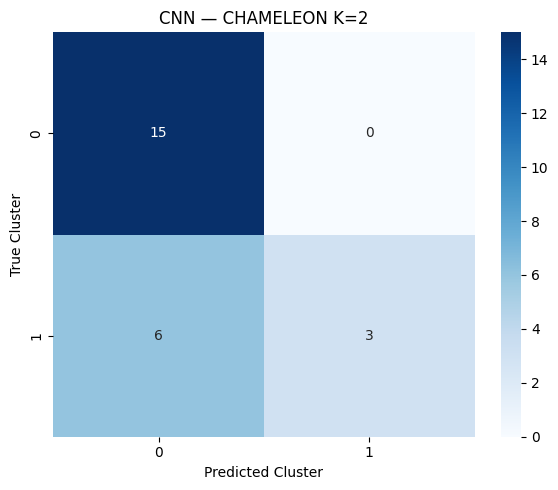

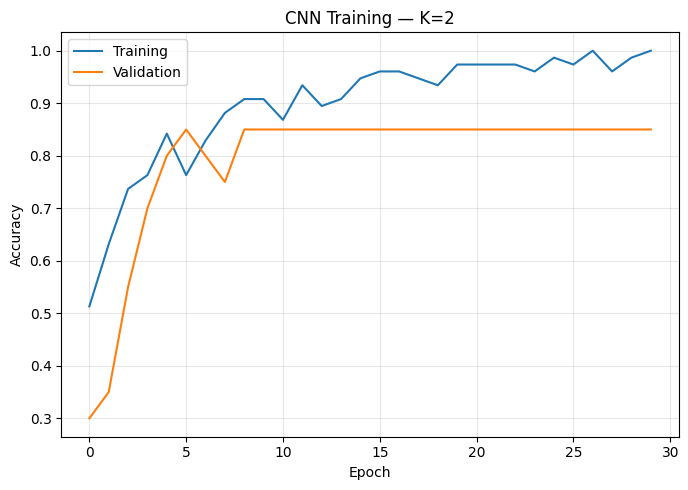



K=2 — LSTM

Cluster distribution:
Cluster 0: 75 observations
Cluster 1: 45 observations

Training observations: 96
Testing observations: 24


-----------------------------------------------------------------
LSTM RESULTS
-----------------------------------------------------------------

Test Accuracy: 0.7083
Balanced Accuracy: 0.6111

Confusion Matrix:
[[15  0]
 [ 7  2]]

Classification Report:
              precision    recall  f1-score   support

           0     0.6818    1.0000    0.8108        15
           1     1.0000    0.2222    0.3636         9

    accuracy                         0.7083        24
   macro avg     0.8409    0.6111    0.5872        24
weighted avg     0.8011    0.7083    0.6431        24



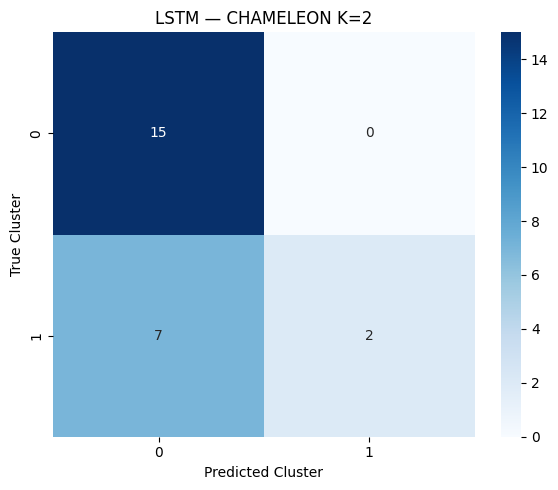

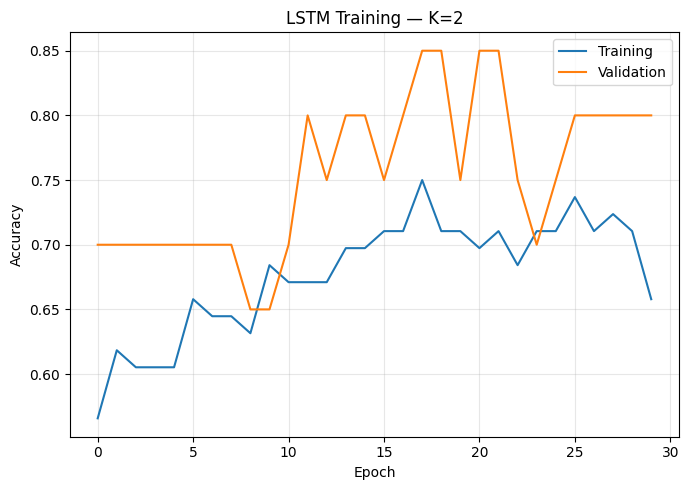



K=2 — CNN-LSTM

Cluster distribution:
Cluster 0: 75 observations
Cluster 1: 45 observations

Training observations: 96
Testing observations: 24


-----------------------------------------------------------------
CNN-LSTM RESULTS
-----------------------------------------------------------------

Test Accuracy: 0.8750
Balanced Accuracy: 0.8333

Confusion Matrix:
[[15  0]
 [ 3  6]]

Classification Report:
              precision    recall  f1-score   support

           0     0.8333    1.0000    0.9091        15
           1     1.0000    0.6667    0.8000         9

    accuracy                         0.8750        24
   macro avg     0.9167    0.8333    0.8545        24
weighted avg     0.8958    0.8750    0.8682        24



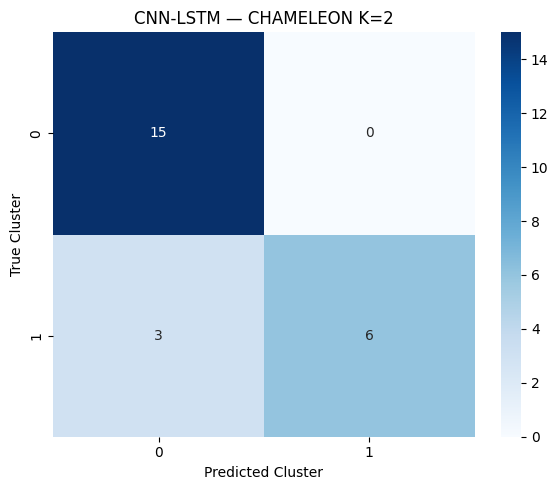

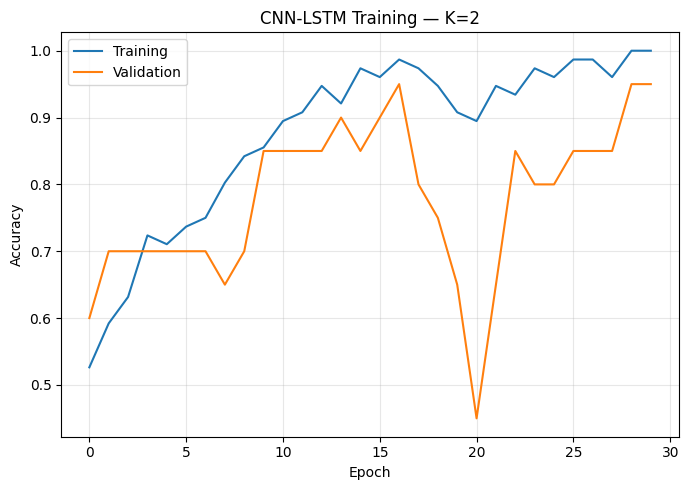



K=3 — CNN

Cluster distribution:
Cluster 0: 15 observations
Cluster 1: 75 observations
Cluster 2: 30 observations

Training observations: 96
Testing observations: 24


-----------------------------------------------------------------
CNN RESULTS
-----------------------------------------------------------------

Test Accuracy: 0.6667
Balanced Accuracy: 0.4444

Confusion Matrix:
[[ 1  2  0]
 [ 0 15  0]
 [ 0  6  0]]

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    0.3333    0.5000         3
           1     0.6522    1.0000    0.7895        15
           2     0.0000    0.0000    0.0000         6

    accuracy                         0.6667        24
   macro avg     0.5507    0.4444    0.4298        24
weighted avg     0.5326    0.6667    0.5559        24



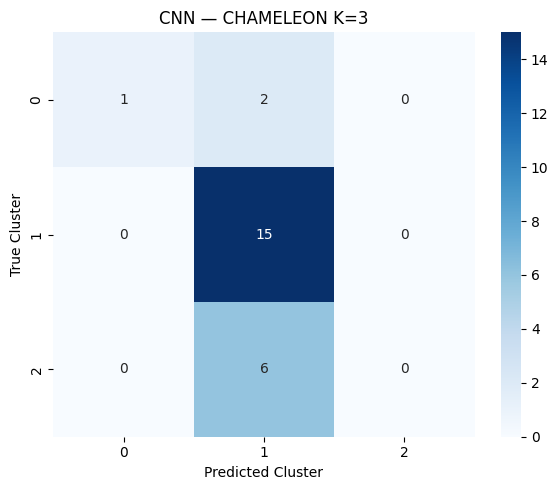

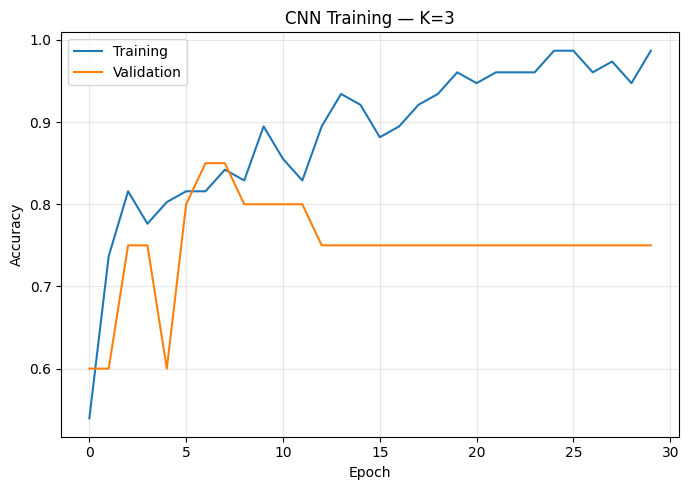



K=3 — LSTM

Cluster distribution:
Cluster 0: 15 observations
Cluster 1: 75 observations
Cluster 2: 30 observations

Training observations: 96
Testing observations: 24




-----------------------------------------------------------------
LSTM RESULTS
-----------------------------------------------------------------

Test Accuracy: 0.6250
Balanced Accuracy: 0.4222

Confusion Matrix:
[[ 1  2  0]
 [ 0 14  1]
 [ 0  6  0]]

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    0.3333    0.5000         3
           1     0.6364    0.9333    0.7568        15
           2     0.0000    0.0000    0.0000         6

    accuracy                         0.6250        24
   macro avg     0.5455    0.4222    0.4189        24
weighted avg     0.5227    0.6250    0.5355        24



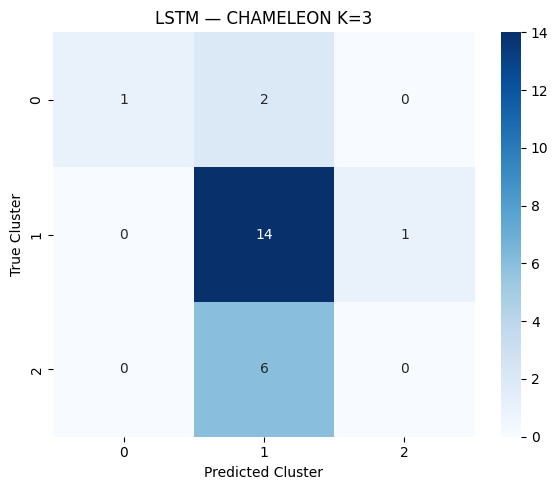

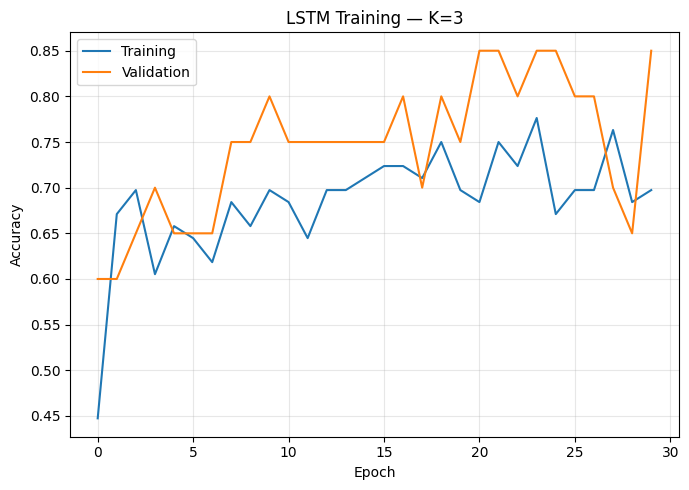



K=3 — CNN-LSTM

Cluster distribution:
Cluster 0: 15 observations
Cluster 1: 75 observations
Cluster 2: 30 observations

Training observations: 96
Testing observations: 24




-----------------------------------------------------------------
CNN-LSTM RESULTS
-----------------------------------------------------------------

Test Accuracy: 0.7083
Balanced Accuracy: 0.5000

Confusion Matrix:
[[ 1  2  0]
 [ 0 15  0]
 [ 0  5  1]]

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    0.3333    0.5000         3
           1     0.6818    1.0000    0.8108        15
           2     1.0000    0.1667    0.2857         6

    accuracy                         0.7083        24
   macro avg     0.8939    0.5000    0.5322        24
weighted avg     0.8011    0.7083    0.6407        24



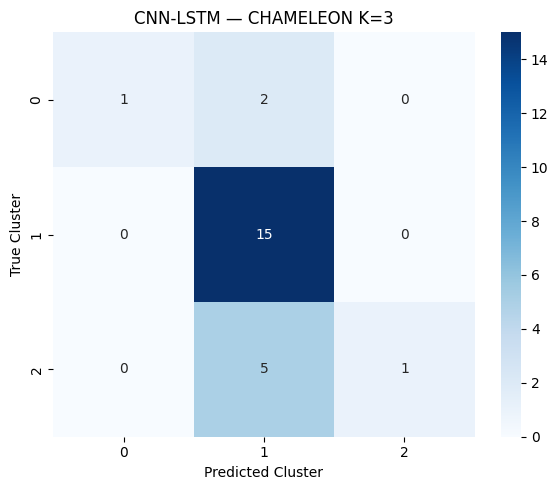

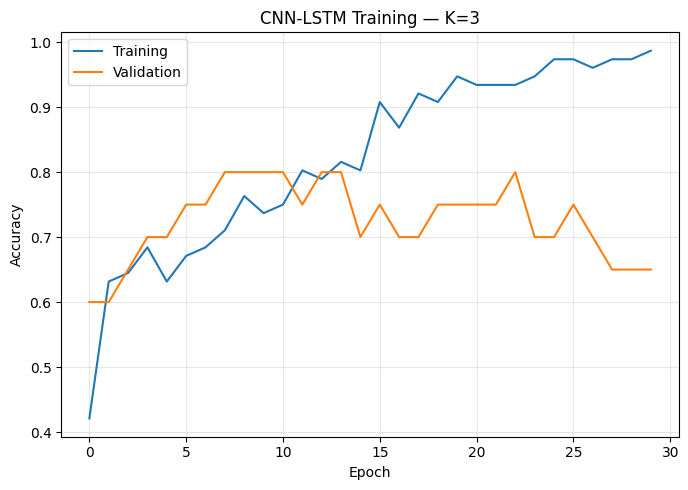



K=4 — CNN

Cluster distribution:
Cluster 0: 7 observations
Cluster 1: 15 observations
Cluster 2: 23 observations
Cluster 3: 75 observations

Training observations: 96
Testing observations: 24


-----------------------------------------------------------------
CNN RESULTS
-----------------------------------------------------------------

Test Accuracy: 0.6250
Balanced Accuracy: 0.4833

Confusion Matrix:
[[0 0 1 0]
 [2 1 0 0]
 [0 0 5 0]
 [4 0 2 9]]

Classification Report:
              precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000         1
           1     1.0000    0.3333    0.5000         3
           2     0.6250    1.0000    0.7692         5
           3     1.0000    0.6000    0.7500        15

    accuracy                         0.6250        24
   macro avg     0.6562    0.4833    0.5048        24
weighted avg     0.8802    0.6250    0.6915        24



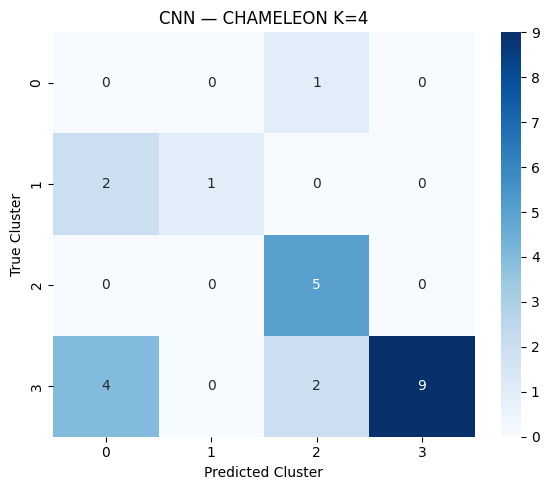

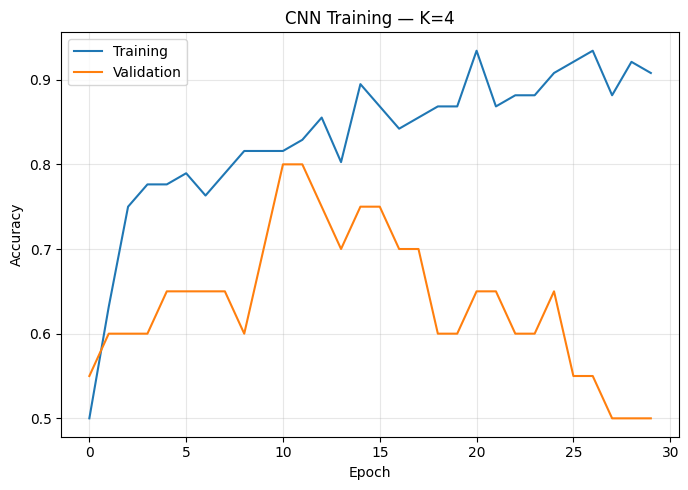



K=4 — LSTM

Cluster distribution:
Cluster 0: 7 observations
Cluster 1: 15 observations
Cluster 2: 23 observations
Cluster 3: 75 observations

Training observations: 96
Testing observations: 24


-----------------------------------------------------------------
LSTM RESULTS
-----------------------------------------------------------------

Test Accuracy: 0.6667
Balanced Accuracy: 0.3333

Confusion Matrix:
[[ 0  0  0  1]
 [ 0  0  0  3]
 [ 0  0  2  3]
 [ 0  0  1 14]]

Classification Report:
              precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000         1
           1     0.0000    0.0000    0.0000         3
           2     0.6667    0.4000    0.5000         5
           3     0.6667    0.9333    0.7778        15

    accuracy                         0.6667        24
   macro avg     0.3333    0.3333    0.3194        24
weighted avg     0.5556    0.6667    0.5903        24



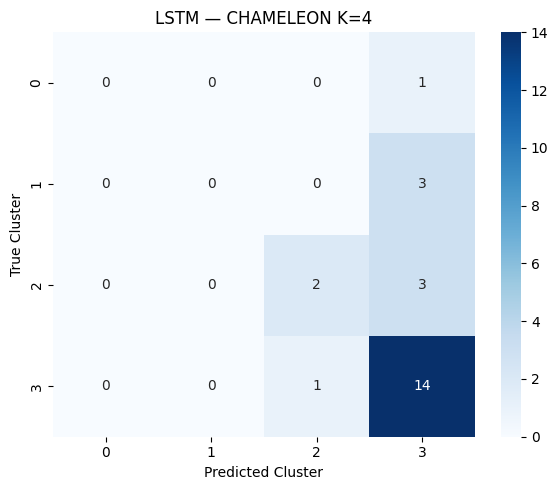

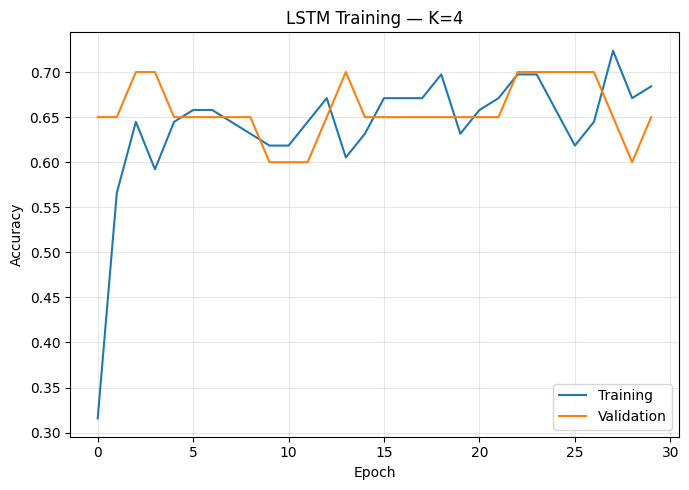



K=4 — CNN-LSTM

Cluster distribution:
Cluster 0: 7 observations
Cluster 1: 15 observations
Cluster 2: 23 observations
Cluster 3: 75 observations

Training observations: 96
Testing observations: 24


-----------------------------------------------------------------
CNN-LSTM RESULTS
-----------------------------------------------------------------

Test Accuracy: 0.7083
Balanced Accuracy: 0.6500

Confusion Matrix:
[[ 1  0  0  0]
 [ 2  1  0  0]
 [ 1  0  2  2]
 [ 1  1  0 13]]

Classification Report:
              precision    recall  f1-score   support

           0     0.2000    1.0000    0.3333         1
           1     0.5000    0.3333    0.4000         3
           2     1.0000    0.4000    0.5714         5
           3     0.8667    0.8667    0.8667        15

    accuracy                         0.7083        24
   macro avg     0.6417    0.6500    0.5429        24
weighted avg     0.8208    0.7083    0.7246        24



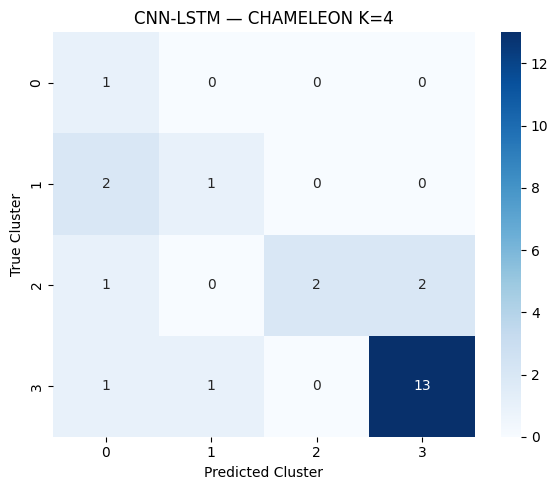

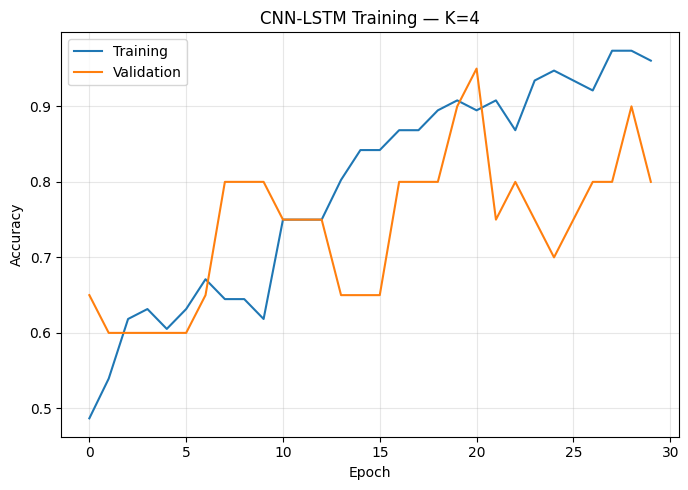



PHASE 10 — FINAL CLASSIFICATION COMPARISON


,K,Model,Accuracy,Balanced_Accuracy
0,2,CNN,0.750000,0.666667
1,2,LSTM,0.708333,0.611111
2,2,CNN-LSTM,0.875000,0.833333
3,3,CNN,0.666667,0.444444
4,3,LSTM,0.625000,0.422222
5,3,CNN-LSTM,0.708333,0.500000
6,4,CNN,0.625000,0.483333
7,4,LSTM,0.666667,0.333333
8,4,CNN-LSTM,0.708333,0.650000


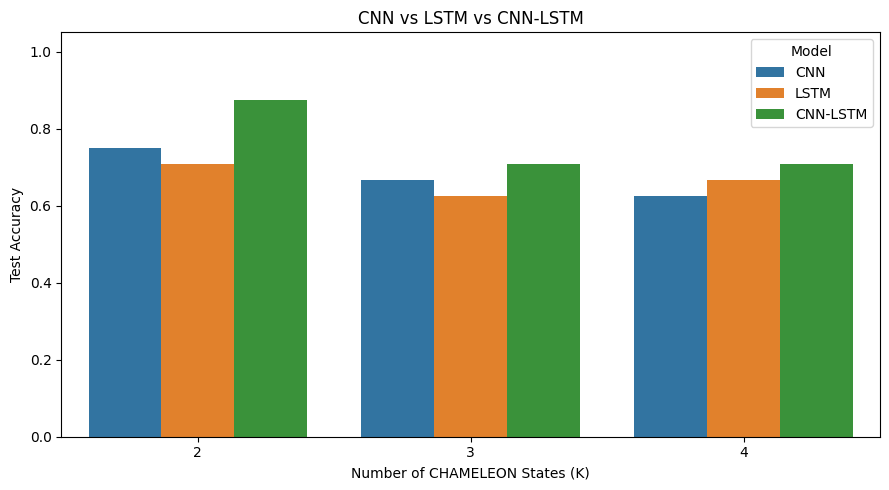

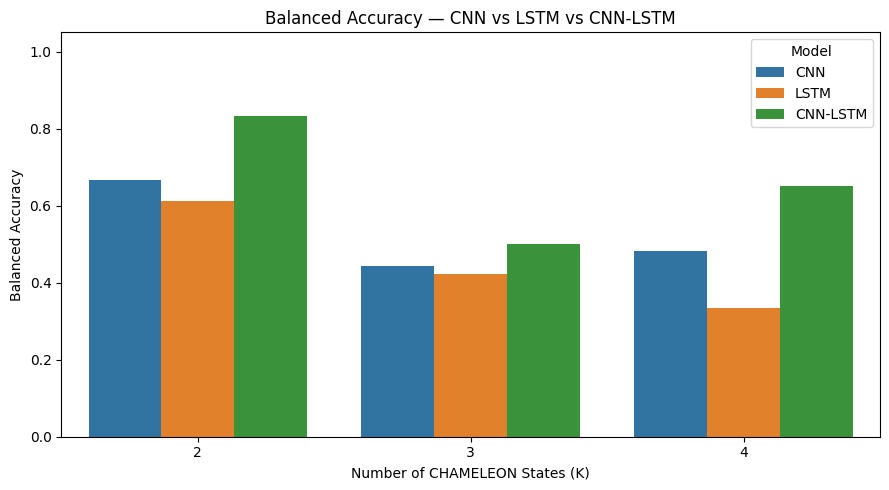



PHASE 10 COMPLETE

Classification target:
CHAMELEON-derived EEG states

Stress_Rating:
NOT used as classification target

Models evaluated:
1. CNN
2. LSTM
3. CNN-LSTM

K values:
[2, 3, 4]

Results:


,K,Model,Accuracy,Balanced_Accuracy
0,2,CNN,0.750000,0.666667
1,2,LSTM,0.708333,0.611111
2,2,CNN-LSTM,0.875000,0.833333
3,3,CNN,0.666667,0.444444
4,3,LSTM,0.625000,0.422222
5,3,CNN-LSTM,0.708333,0.500000
6,4,CNN,0.625000,0.483333
7,4,LSTM,0.666667,0.333333
8,4,CNN-LSTM,0.708333,0.650000



Saved:
/content/drive/MyDrive/Journal/SAM40_trial1_Phase10_EEG_State_Classification.csv


In [26]:
# ============================================================
# PHASE 10 — EEG-DERIVED STATE CLASSIFICATION
#
# PURPOSE
# ------------------------------------------------------------
# Test whether the EEG-derived CHAMELEON states from Phase 9
# can be learned and classified using:
#
#     1. CNN
#     2. LSTM
#     3. CNN + LSTM
#
# IMPORTANT
# ------------------------------------------------------------
# Classification target:
#
#     CHAMELEON-derived EEG state
#
# Stress_Rating:
#
#     NOT used as classification target
#
# EEG representation:
#
#     Stress EEG - Subject-specific Relaxation baseline
#
# EEG features:
#
#     640
#
# Cluster labels come directly from:
#
#     cluster_solutions[K]['labels']
#
# produced by Phase 9.
#
# K values:
#
#     K = 2
#     K = 3
#     K = 4
#
# ============================================================


# ============================================================
# 10.1 IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    GlobalAveragePooling1D,
    LSTM,
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns

import random
import os


# ============================================================
# 10.2 REPRODUCIBILITY
# ============================================================

SEED = 42

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

os.environ['PYTHONHASHSEED'] = str(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass


# ============================================================
# 10.3 PARAMETERS
# ============================================================

TARGET_K_VALUES = [2, 3, 4]

TEST_SIZE = 0.20

EPOCHS = 30

BATCH_SIZE = 16

LEARNING_RATE = 0.001


# ============================================================
# 10.4 CHECK REQUIRED PHASE 9 VARIABLES
# ============================================================

required_variables = [

    'X_deviation',

    'cluster_solutions',

    'eeg_feature_columns',

    'stress_cluster_df'
]


missing_variables = []

for variable in required_variables:

    if variable not in globals():

        missing_variables.append(variable)


if len(missing_variables) > 0:

    raise RuntimeError(
        "\nPHASE 10 ERROR\n"
        "The following required variables are missing:\n"
        f"{missing_variables}\n\n"
        "Please run Phase 9 before Phase 10."
    )


# ============================================================
# 10.5 EEG INPUT MATRIX
# ============================================================

X = np.asarray(
    X_deviation,
    dtype=np.float32
)


print("=" * 75)
print("PHASE 10 — EEG-DERIVED STATE CLASSIFICATION")
print("=" * 75)

print(
    "\nClassification target:"
)

print(
    "CHAMELEON-derived EEG state"
)

print(
    "\nStress_Rating:"
)

print(
    "NOT used as classification target"
)

print(
    "\nEEG representation:"
)

print(
    "Stress EEG - Subject-specific Relaxation baseline"
)

print(
    "\nEEG feature matrix:"
)

print(
    X.shape
)


# ============================================================
# 10.6 BASIC INPUT CHECK
# ============================================================

if X.ndim != 2:

    raise ValueError(
        "X_deviation must be a 2D matrix."
    )


if X.shape[1] != len(
    eeg_feature_columns
):

    raise ValueError(
        "Mismatch between X_deviation "
        "and eeg_feature_columns."
    )


print(
    "\nNumber of observations:",
    X.shape[0]
)

print(
    "Number of EEG features:",
    X.shape[1]
)


# ============================================================
# 10.7 MODEL DEFINITIONS
# ============================================================

def build_cnn(
    input_length,
    num_classes
):

    model = Sequential([

        Input(
            shape=(
                input_length,
                1
            )
        ),

        Conv1D(
            filters=32,
            kernel_size=5,
            activation='relu',
            padding='same'
        ),

        BatchNormalization(),

        MaxPooling1D(
            pool_size=2
        ),

        Dropout(0.30),


        Conv1D(
            filters=64,
            kernel_size=3,
            activation='relu',
            padding='same'
        ),

        BatchNormalization(),

        MaxPooling1D(
            pool_size=2
        ),

        Dropout(0.30),


        GlobalAveragePooling1D(),


        Dense(
            64,
            activation='relu'
        ),

        Dropout(0.30),


        Dense(
            num_classes,
            activation='softmax'
        )
    ])


    model.compile(

        optimizer=Adam(
            learning_rate=LEARNING_RATE
        ),

        loss='sparse_categorical_crossentropy',

        metrics=['accuracy']
    )


    return model


# ============================================================

def build_lstm(
    input_length,
    num_classes
):

    model = Sequential([

        Input(
            shape=(
                input_length,
                1
            )
        ),

        LSTM(
            64,
            return_sequences=True
        ),

        Dropout(0.30),

        LSTM(
            32
        ),

        Dropout(0.30),


        Dense(
            64,
            activation='relu'
        ),

        Dropout(0.30),


        Dense(
            num_classes,
            activation='softmax'
        )
    ])


    model.compile(

        optimizer=Adam(
            learning_rate=LEARNING_RATE
        ),

        loss='sparse_categorical_crossentropy',

        metrics=['accuracy']
    )


    return model


# ============================================================

def build_cnn_lstm(
    input_length,
    num_classes
):

    model = Sequential([

        Input(
            shape=(
                input_length,
                1
            )
        ),


        Conv1D(
            filters=32,
            kernel_size=5,
            activation='relu',
            padding='same'
        ),

        BatchNormalization(),

        MaxPooling1D(
            pool_size=2
        ),

        Dropout(0.30),


        Conv1D(
            filters=64,
            kernel_size=3,
            activation='relu',
            padding='same'
        ),

        BatchNormalization(),

        MaxPooling1D(
            pool_size=2
        ),

        Dropout(0.30),


        LSTM(
            64,
            return_sequences=True
        ),

        Dropout(0.30),

        LSTM(
            32
        ),

        Dropout(0.30),


        Dense(
            64,
            activation='relu'
        ),

        Dropout(0.30),


        Dense(
            num_classes,
            activation='softmax'
        )
    ])


    model.compile(

        optimizer=Adam(
            learning_rate=LEARNING_RATE
        ),

        loss='sparse_categorical_crossentropy',

        metrics=['accuracy']
    )


    return model


# ============================================================
# 10.8 CLASSIFICATION FUNCTION
# ============================================================

def run_classification(
    X_input,
    labels,
    K,
    model_name
):

    print("\n")
    print("=" * 75)

    print(
        f"K={K} — {model_name}"
    )

    print("=" * 75)


    # --------------------------------------------------------
    # Convert labels
    # --------------------------------------------------------

    y = np.asarray(
        labels,
        dtype=np.int32
    )


    # --------------------------------------------------------
    # Check number of classes
    # --------------------------------------------------------

    unique_classes = np.unique(y)

    num_classes = len(
        unique_classes
    )


    if num_classes != K:

        raise ValueError(
            f"K={K} but found "
            f"{num_classes} unique labels: "
            f"{unique_classes}"
        )


    # --------------------------------------------------------
    # Cluster distribution
    # --------------------------------------------------------

    print(
        "\nCluster distribution:"
    )

    for cluster_id in unique_classes:

        count = np.sum(
            y == cluster_id
        )

        print(
            f"Cluster {cluster_id}: "
            f"{count} observations"
        )


    # --------------------------------------------------------
    # Stratified train/test split
    # --------------------------------------------------------

    X_train, X_test, y_train, y_test = (
        train_test_split(

            X_input,

            y,

            test_size=TEST_SIZE,

            stratify=y,

            random_state=SEED
        )
    )


    print(
        "\nTraining observations:",
        len(X_train)
    )

    print(
        "Testing observations:",
        len(X_test)
    )


    # --------------------------------------------------------
    # Standardisation
    #
    # IMPORTANT:
    # Fit scaler ONLY on training data.
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train = scaler.fit_transform(
        X_train
    )

    X_test = scaler.transform(
        X_test
    )


    # --------------------------------------------------------
    # Reshape for CNN/LSTM
    #
    # Shape:
    #
    #     observations
    #     × EEG features
    #     × 1
    #
    # --------------------------------------------------------

    X_train = X_train.reshape(
        X_train.shape[0],
        X_train.shape[1],
        1
    )

    X_test = X_test.reshape(
        X_test.shape[0],
        X_test.shape[1],
        1
    )


    # --------------------------------------------------------
    # Build model
    # --------------------------------------------------------

    if model_name == 'CNN':

        model = build_cnn(
            X_train.shape[1],
            num_classes
        )


    elif model_name == 'LSTM':

        model = build_lstm(
            X_train.shape[1],
            num_classes
        )


    elif model_name == 'CNN-LSTM':

        model = build_cnn_lstm(
            X_train.shape[1],
            num_classes
        )


    else:

        raise ValueError(
            "Unknown model."
        )


    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    history = model.fit(

        X_train,

        y_train,

        validation_split=0.20,

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        verbose=0,

        shuffle=True
    )


    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    y_probability = model.predict(
        X_test,
        verbose=0
    )

    y_pred = np.argmax(
        y_probability,
        axis=1
    )


    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    balanced_accuracy = (
        balanced_accuracy_score(
            y_test,
            y_pred
        )
    )


    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=unique_classes
    )


    # --------------------------------------------------------
    # Results
    # --------------------------------------------------------

    print("\n")
    print(
        "-" * 65
    )

    print(
        f"{model_name} RESULTS"
    )

    print(
        "-" * 65
    )


    print(
        f"\nTest Accuracy: "
        f"{accuracy:.4f}"
    )

    print(
        f"Balanced Accuracy: "
        f"{balanced_accuracy:.4f}"
    )


    print(
        "\nConfusion Matrix:"
    )

    print(
        cm
    )


    print(
        "\nClassification Report:"
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=unique_classes,
            digits=4,
            zero_division=0
        )
    )


    # --------------------------------------------------------
    # Confusion matrix figure
    # --------------------------------------------------------

    plt.figure(
        figsize=(6, 5)
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=unique_classes,
        yticklabels=unique_classes
    )

    plt.xlabel(
        'Predicted Cluster'
    )

    plt.ylabel(
        'True Cluster'
    )

    plt.title(
        f'{model_name} — CHAMELEON K={K}'
    )

    plt.tight_layout()

    plt.show()


    # --------------------------------------------------------
    # Training curve
    # --------------------------------------------------------

    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        history.history['accuracy'],
        label='Training'
    )

    plt.plot(
        history.history['val_accuracy'],
        label='Validation'
    )

    plt.xlabel(
        'Epoch'
    )

    plt.ylabel(
        'Accuracy'
    )

    plt.title(
        f'{model_name} Training — K={K}'
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # --------------------------------------------------------
    # Return results
    # --------------------------------------------------------

    return {

        'K':
            K,

        'Model':
            model_name,

        'Accuracy':
            accuracy,

        'Balanced_Accuracy':
            balanced_accuracy
    }


# ============================================================
# 10.9 RUN ALL THREE MODELS
# ============================================================

all_results = []


for K in TARGET_K_VALUES:


    # --------------------------------------------------------
    # IMPORTANT:
    #
    # Phase 9 stores labels here:
    #
    #     cluster_solutions[K]['labels']
    #
    # NOT:
    #
    #     cluster_labels
    # --------------------------------------------------------

    labels = np.asarray(

        cluster_solutions[K][
            'labels'
        ]

    )


    # --------------------------------------------------------
    # Safety check
    # --------------------------------------------------------

    if len(labels) != X.shape[0]:

        raise ValueError(

            f"K={K}: number of cluster labels "
            f"({len(labels)}) does not match "
            f"EEG observations ({X.shape[0]})."

        )


    # --------------------------------------------------------
    # CNN
    # --------------------------------------------------------

    result = run_classification(

        X_input=X,

        labels=labels,

        K=K,

        model_name='CNN'
    )

    all_results.append(
        result
    )


    # --------------------------------------------------------
    # LSTM
    # --------------------------------------------------------

    result = run_classification(

        X_input=X,

        labels=labels,

        K=K,

        model_name='LSTM'
    )

    all_results.append(
        result
    )


    # --------------------------------------------------------
    # CNN + LSTM
    # --------------------------------------------------------

    result = run_classification(

        X_input=X,

        labels=labels,

        K=K,

        model_name='CNN-LSTM'
    )

    all_results.append(
        result
    )


# ============================================================
# 10.10 FINAL RESULTS TABLE
# ============================================================

classification_results_df = pd.DataFrame(
    all_results
)


print("\n")
print("=" * 75)
print("PHASE 10 — FINAL CLASSIFICATION COMPARISON")
print("=" * 75)


display(
    classification_results_df
)


# ============================================================
# 10.11 ACCURACY COMPARISON
# ============================================================

plt.figure(
    figsize=(9, 5)
)

sns.barplot(
    data=classification_results_df,
    x='K',
    y='Accuracy',
    hue='Model'
)

plt.ylim(
    0,
    1.05
)

plt.xlabel(
    'Number of CHAMELEON States (K)'
)

plt.ylabel(
    'Test Accuracy'
)

plt.title(
    'CNN vs LSTM vs CNN-LSTM'
)

plt.tight_layout()

plt.show()


# ============================================================
# 10.12 BALANCED ACCURACY COMPARISON
# ============================================================

plt.figure(
    figsize=(9, 5)
)

sns.barplot(
    data=classification_results_df,
    x='K',
    y='Balanced_Accuracy',
    hue='Model'
)

plt.ylim(
    0,
    1.05
)

plt.xlabel(
    'Number of CHAMELEON States (K)'
)

plt.ylabel(
    'Balanced Accuracy'
)

plt.title(
    'Balanced Accuracy — CNN vs LSTM vs CNN-LSTM'
)

plt.tight_layout()

plt.show()


# ============================================================
# 10.13 SAVE RESULTS
# ============================================================

output_directory = (
    '/content/drive/MyDrive/Journal/'
)


output_path = (
    output_directory +
    'SAM40_trial1_Phase10_EEG_State_Classification.csv'
)


classification_results_df.to_csv(
    output_path,
    index=False
)


# ============================================================
# 10.14 FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 75)
print("PHASE 10 COMPLETE")
print("=" * 75)


print(
    "\nClassification target:"
)

print(
    "CHAMELEON-derived EEG states"
)


print(
    "\nStress_Rating:"
)

print(
    "NOT used as classification target"
)


print(
    "\nModels evaluated:"
)

print(
    "1. CNN"
)

print(
    "2. LSTM"
)

print(
    "3. CNN-LSTM"
)


print(
    "\nK values:"
)

print(
    TARGET_K_VALUES
)


print(
    "\nResults:"
)

display(
    classification_results_df
)


print(
    "\nSaved:"
)

print(
    output_path
)

In [29]:
# ============================================================
# PHASE 10B — SUBJECT-WISE EEG-DERIVED STATE CLASSIFICATION (Table 7)
#
# PURPOSE
# ------------------------------------------------------------
# Evaluate the SELECTED K=2 CHAMELEON state solution using a
# subject-wise 80/20 train-test split.
#
# TABLE 6:
#   Initial observation-level stratified evaluation
#   K = 2, 3, 4
#   Used to compare CNN, LSTM, and CNN-LSTM and select K.
#
# TABLE 7:
#   Subject-wise evaluation of the selected K=2 solution
#   CNN, LSTM, and CNN-LSTM
#
# IMPORTANT:
# ------------------------------------------------------------
# Classification target:
#   CHAMELEON-derived EEG state
#
# Stress_Rating:
#   NOT used as classification target
#
# EEG representation:
#   Stress EEG - Subject-specific Relaxation baseline
#
# EEG features:
#   640 EEG deviation features
#
# DATA SPLIT:
#   Subject-wise 80/20 split using GroupShuffleSplit
#
# The same participant-level train/test split is used for all
# three models.
# ============================================================


# ============================================================
# 10B.1 IMPORTS
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    GlobalAveragePooling1D,
    LSTM,
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.optimizers import Adam


# ============================================================
# 10B.2 REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass


# ============================================================
# 10B.3 PARAMETERS
# ============================================================

# K=2 was selected from the initial Table 6 evaluation.
TARGET_K = 2

TEST_SIZE = 0.20

EPOCHS = 30

BATCH_SIZE = 16

LEARNING_RATE = 0.001


# ============================================================
# 10B.4 CHECK PHASE 9 VARIABLES
# ============================================================

required_variables = [
    "stress_cluster_df",
    "X_deviation",
    "cluster_solutions",
    "eeg_feature_columns"
]

missing_variables = []

for variable in required_variables:

    if variable not in globals():
        missing_variables.append(variable)

if len(missing_variables) > 0:

    raise RuntimeError(
        "\nPHASE 10B ERROR\n"
        "The following required variables are missing:\n"
        f"{missing_variables}\n\n"
        "Please run Phase 9 and Phase 9B first."
    )


# ============================================================
# 10B.5 FIND SUBJECT IDENTIFIER
# ============================================================

possible_subject_columns = [
    "Subject",
    "Subject_ID",
    "SubjectID",
    "subject",
    "subject_id",
    "participant",
    "Participant",
    "Participant_ID"
]

subject_column = None

for col in possible_subject_columns:

    if col in stress_cluster_df.columns:

        subject_column = col
        break


if subject_column is None:

    raise RuntimeError(
        "\nPHASE 10B ERROR\n"
        "Could not find the subject identifier column.\n\n"
        "Available columns are:\n"
        f"{list(stress_cluster_df.columns)}\n\n"
        "Please set subject_column manually."
    )


# ============================================================
# 10B.6 PREPARE EEG MATRIX
# ============================================================

X = np.asarray(
    X_deviation,
    dtype=np.float32
)


if X.ndim != 2:

    raise ValueError(
        "X_deviation must be a 2D matrix."
    )


if X.shape[1] != len(eeg_feature_columns):

    raise ValueError(
        "Mismatch between X_deviation and "
        "eeg_feature_columns."
    )


groups = (
    stress_cluster_df[
        subject_column
    ].values
)


if len(groups) != X.shape[0]:

    raise ValueError(
        "Number of subject identifiers does not "
        "match number of EEG observations."
    )


print("=" * 75)
print("PHASE 10B — SUBJECT-WISE K=2 CLASSIFICATION")
print("=" * 75)

print(
    "\nSelected K:",
    TARGET_K
)

print(
    "Subject identifier:",
    subject_column
)

print(
    "EEG representation:",
    "Stress EEG - Subject-specific Relaxation baseline"
)

print(
    "Number of observations:",
    X.shape[0]
)

print(
    "Number of EEG features:",
    X.shape[1]
)

print(
    "Stress_Rating:",
    "NOT used as classification target"
)

print(
    "Split:",
    "Subject-wise 80/20"
)


# ============================================================
# 10B.7 GET K=2 CHAMELEON LABELS
# ============================================================

labels = np.asarray(
    cluster_solutions[TARGET_K]["labels"],
    dtype=np.int32
)


if len(labels) != X.shape[0]:

    raise ValueError(
        "Number of K=2 cluster labels does not "
        "match number of EEG observations."
    )


unique_classes = np.unique(labels)


if len(unique_classes) != TARGET_K:

    raise ValueError(
        f"Expected {TARGET_K} classes but found "
        f"{len(unique_classes)}: {unique_classes}"
    )


print("\nK=2 cluster distribution:")

for cluster_id in unique_classes:

    count = np.sum(
        labels == cluster_id
    )

    print(
        f"Cluster {cluster_id}: "
        f"{count} observations"
    )


# ============================================================
# 10B.8 FIXED SUBJECT-WISE 80/20 SPLIT
# ============================================================

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=TEST_SIZE,
    random_state=SEED
)


train_indices, test_indices = next(
    gss.split(
        X,
        labels,
        groups=groups
    )
)


train_indices = np.sort(
    train_indices
)

test_indices = np.sort(
    test_indices
)


train_subjects = np.unique(
    groups[train_indices]
)

test_subjects = np.unique(
    groups[test_indices]
)


# ============================================================
# 10B.9 VERIFY SUBJECT SEPARATION
# ============================================================

overlap = set(
    train_subjects
).intersection(
    set(test_subjects)
)


if len(overlap) > 0:

    raise RuntimeError(
        f"SUBJECT LEAKAGE DETECTED: {overlap}"
    )


print("\n")
print("-" * 75)
print("SUBJECT-WISE SPLIT")
print("-" * 75)

print(
    "Training observations:",
    len(train_indices)
)

print(
    "Testing observations:",
    len(test_indices)
)

print(
    "Training subjects:",
    len(train_subjects)
)

print(
    "Testing subjects:",
    len(test_subjects)
)

print(
    "\n✓ No subject appears in both "
    "training and testing."
)


# ============================================================
# 10B.10 SAVE PARTICIPANT-LEVEL SPLIT
# ============================================================

split_records = []

for idx in train_indices:

    split_records.append({

        "observation_index": int(idx),

        "participant_id":
            groups[idx],

        "split":
            "train",

        "CHAMELEON_state":
            int(labels[idx])

    })


for idx in test_indices:

    split_records.append({

        "observation_index": int(idx),

        "participant_id":
            groups[idx],

        "split":
            "test",

        "CHAMELEON_state":
            int(labels[idx])

    })


split_df = pd.DataFrame(
    split_records
)


# ============================================================
# 10B.11 STANDARDIZATION
# ============================================================
#
# IMPORTANT:
# Fit the scaler ONLY on training observations.
# ============================================================

scaler = StandardScaler()


X_train_scaled = scaler.fit_transform(
    X[train_indices]
)


X_test_scaled = scaler.transform(
    X[test_indices]
)


# ============================================================
# 10B.12 RESHAPE FOR CNN/LSTM
# ============================================================

X_train_nn = X_train_scaled.reshape(
    X_train_scaled.shape[0],
    X_train_scaled.shape[1],
    1
)


X_test_nn = X_test_scaled.reshape(
    X_test_scaled.shape[0],
    X_test_scaled.shape[1],
    1
)


# ============================================================
# 10B.13 MODEL DEFINITIONS
# ============================================================

def build_cnn_model(
    num_classes,
    input_shape
):

    model = Sequential([

        Input(
            shape=input_shape
        ),

        Conv1D(
            filters=32,
            kernel_size=5,
            activation="relu",
            padding="same"
        ),

        BatchNormalization(),

        MaxPooling1D(
            pool_size=2
        ),

        Dropout(0.30),

        Conv1D(
            filters=64,
            kernel_size=3,
            activation="relu",
            padding="same"
        ),

        BatchNormalization(),

        MaxPooling1D(
            pool_size=2
        ),

        Dropout(0.30),

        GlobalAveragePooling1D(),

        Dense(
            64,
            activation="relu"
        ),

        Dropout(0.30),

        Dense(
            num_classes,
            activation="softmax"
        )

    ])


    model.compile(

        optimizer=Adam(
            learning_rate=LEARNING_RATE
        ),

        loss="sparse_categorical_crossentropy",

        metrics=["accuracy"]
    )

    return model


# ------------------------------------------------------------

def build_lstm_model(
    num_classes,
    input_shape
):

    model = Sequential([

        Input(
            shape=input_shape
        ),

        LSTM(
            64,
            return_sequences=True
        ),

        Dropout(0.30),

        LSTM(
            32
        ),

        Dropout(0.30),

        Dense(
            64,
            activation="relu"
        ),

        Dropout(0.30),

        Dense(
            num_classes,
            activation="softmax"
        )

    ])


    model.compile(

        optimizer=Adam(
            learning_rate=LEARNING_RATE
        ),

        loss="sparse_categorical_crossentropy",

        metrics=["accuracy"]
    )

    return model


# ------------------------------------------------------------

def build_cnn_lstm_model(
    num_classes,
    input_shape
):

    model = Sequential([

        Input(
            shape=input_shape
        ),

        Conv1D(
            filters=32,
            kernel_size=5,
            activation="relu",
            padding="same"
        ),

        BatchNormalization(),

        MaxPooling1D(
            pool_size=2
        ),

        Dropout(0.30),

        Conv1D(
            filters=64,
            kernel_size=3,
            activation="relu",
            padding="same"
        ),

        BatchNormalization(),

        MaxPooling1D(
            pool_size=2
        ),

        Dropout(0.30),

        LSTM(
            64,
            return_sequences=True
        ),

        Dropout(0.30),

        LSTM(
            32
        ),

        Dropout(0.30),

        Dense(
            64,
            activation="relu"
        ),

        Dropout(0.30),

        Dense(
            num_classes,
            activation="softmax"
        )

    ])


    model.compile(

        optimizer=Adam(
            learning_rate=LEARNING_RATE
        ),

        loss="sparse_categorical_crossentropy",

        metrics=["accuracy"]
    )

    return model


# ============================================================
# 10B.14 CLASSIFICATION FUNCTION
# ============================================================

def run_classification(
    model_name,
    build_function
):

    print("\n")
    print("=" * 75)
    print(
        f"K={TARGET_K} — {model_name} "
        "— SUBJECT-WISE"
    )
    print("=" * 75)


    # --------------------------------------------------------
    # Training and testing labels
    # --------------------------------------------------------

    y_train = labels[
        train_indices
    ]

    y_test = labels[
        test_indices
    ]


    # --------------------------------------------------------
    # Verify all test classes exist in training
    # --------------------------------------------------------

    missing_test_classes = (
        set(np.unique(y_test))
        -
        set(np.unique(y_train))
    )


    if len(missing_test_classes) > 0:

        raise ValueError(
            "The subject-wise split contains test "
            "class(es) not present in training: "
            f"{missing_test_classes}"
        )


    # --------------------------------------------------------
    # Reproducibility before model creation
    # --------------------------------------------------------

    tf.keras.backend.clear_session()

    tf.random.set_seed(
        SEED
    )

    np.random.seed(
        SEED
    )

    random.seed(
        SEED
    )


    # --------------------------------------------------------
    # Build model
    # --------------------------------------------------------

    model = build_function(

        num_classes=TARGET_K,

        input_shape=(
            X_train_nn.shape[1],
            1
        )

    )


    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    history = model.fit(

        X_train_nn,

        y_train,

        validation_split=0.20,

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        shuffle=True,

        verbose=0
    )


    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    y_probability = model.predict(

        X_test_nn,

        verbose=0

    )


    y_pred = np.argmax(

        y_probability,

        axis=1

    )


    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(

        y_test,

        y_pred

    )


    balanced_accuracy = (
        balanced_accuracy_score(

            y_test,

            y_pred

        )
    )


    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------

    cm = confusion_matrix(

        y_test,

        y_pred,

        labels=np.arange(TARGET_K)

    )


    # --------------------------------------------------------
    # Print results
    # --------------------------------------------------------

    print("\n")
    print("-" * 65)

    print(
        f"{model_name} RESULTS"
    )

    print("-" * 65)

    print(
        f"\nTest Accuracy: "
        f"{accuracy:.4f}"
    )

    print(
        f"Balanced Accuracy: "
        f"{balanced_accuracy:.4f}"
    )

    print(
        "\nConfusion Matrix:"
    )

    print(
        cm
    )


    print(
        "\nClassification Report:"
    )

    print(

        classification_report(

            y_test,

            y_pred,

            labels=np.arange(TARGET_K),

            digits=4,

            zero_division=0

        )

    )


    # ========================================================
    # SAVE ORIGINAL PREDICTIONS
    # ========================================================

    prediction_df = pd.DataFrame({

        "observation_index":
            test_indices,

        "participant_id":
            groups[test_indices],

        "true_state":
            y_test,

        "predicted_state":
            y_pred

    })


    prediction_df["model"] = model_name

    prediction_df["K"] = TARGET_K


    return {

        "K":
            TARGET_K,

        "Model":
            model_name,

        "Accuracy":
            accuracy,

        "Balanced_Accuracy":
            balanced_accuracy,

        "Confusion_Matrix":
            cm,

        "Y_Test":
            y_test,

        "Y_Pred":
            y_pred,

        "Predictions":
            prediction_df,

        "History":
            history,

        "Model_Object":
            model

    }


# ============================================================
# 10B.15 RUN THREE MODELS FOR K=2
# ============================================================

MODEL_CONFIGS = [

    (
        "CNN",
        build_cnn_model
    ),

    (
        "LSTM",
        build_lstm_model
    ),

    (
        "CNN-LSTM",
        build_cnn_lstm_model
    )

]


classification_results = []

prediction_results = {}

confusion_matrices = {}


for model_name, build_function in MODEL_CONFIGS:

    result = run_classification(

        model_name=model_name,

        build_function=build_function

    )


    classification_results.append({

        "K":
            result["K"],

        "Model":
            result["Model"],

        "Accuracy":
            result["Accuracy"],

        "Balanced_Accuracy":
            result["Balanced_Accuracy"]

    })


    prediction_results[
        model_name
    ] = result["Predictions"]


    confusion_matrices[
        model_name
    ] = result["Confusion_Matrix"]


# ============================================================
# 10B.16 FINAL TABLE 7 RESULTS
# ============================================================

table7_results_df = pd.DataFrame(
    classification_results
)


table7_results_df = (
    table7_results_df
    .sort_values(
        "Balanced_Accuracy",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


print("\n")
print("=" * 75)
print("TABLE 7 — SUBJECT-WISE K=2 RESULTS")
print("=" * 75)


display(
    table7_results_df
)


# ============================================================
# 10B.17 SAVE OUTPUTS
# ============================================================

output_directory = (
    "/content/drive/MyDrive/Journal/Phase10_Table7/"
)


os.makedirs(
    output_directory,
    exist_ok=True
)


# ------------------------------------------------------------
# Table 7 metrics
# ------------------------------------------------------------

table7_results_df.to_csv(

    output_directory +
    "Table7_K2_subjectwise_results.csv",

    index=False

)


# ------------------------------------------------------------
# Participant-level split
# ------------------------------------------------------------

split_df.to_csv(

    output_directory +
    "Table7_K2_participant_split.csv",

    index=False

)


# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

for model_name, prediction_df in (
    prediction_results.items()
):

    prediction_df.to_csv(

        output_directory +
        f"Table7_K2_{model_name}_predictions.csv",

        index=False

    )


# ------------------------------------------------------------
# Confusion matrices
# ------------------------------------------------------------

for model_name, cm in (
    confusion_matrices.items()
):

    cm_df = pd.DataFrame(

        cm,

        index=[
            f"True_State_{i}"
            for i in range(TARGET_K)
        ],

        columns=[
            f"Predicted_State_{i}"
            for i in range(TARGET_K)
        ]

    )


    cm_df.to_csv(

        output_directory +
        f"Table7_K2_{model_name}_confusion_matrix.csv"

    )


print("\n")
print("=" * 75)
print("TABLE 7 OUTPUTS SAVED")
print("=" * 75)

print(
    "\nMetrics:"
)

print(
    "Table7_K2_subjectwise_results.csv"
)

print(
    "\nParticipant split:"
)

print(
    "Table7_K2_participant_split.csv"
)

print(
    "\nOriginal predictions:"
)

print(
    "CNN / LSTM / CNN-LSTM prediction files"
)

print(
    "\nConfusion matrices:"
)

print(
    "CNN / LSTM / CNN-LSTM confusion matrix files"
)

PHASE 10B — SUBJECT-WISE K=2 CLASSIFICATION

Selected K: 2
Subject identifier: Subject
EEG representation: Stress EEG - Subject-specific Relaxation baseline
Number of observations: 120
Number of EEG features: 640
Stress_Rating: NOT used as classification target
Split: Subject-wise 80/20

K=2 cluster distribution:
Cluster 0: 75 observations
Cluster 1: 45 observations


---------------------------------------------------------------------------
SUBJECT-WISE SPLIT
---------------------------------------------------------------------------
Training observations: 96
Testing observations: 24
Training subjects: 32
Testing subjects: 8

✓ No subject appears in both training and testing.


K=2 — CNN — SUBJECT-WISE


-----------------------------------------------------------------
CNN RESULTS
-----------------------------------------------------------------

Test Accuracy: 0.8333
Balanced Accuracy: 0.9000

Confusion Matrix:
[[16  4]
 [ 0  4]]

Classification Report:
              precision    re

,K,Model,Accuracy,Balanced_Accuracy
0,2,CNN-LSTM,0.875000,0.925
1,2,CNN,0.833333,0.900
2,2,LSTM,0.541667,0.525




TABLE 7 OUTPUTS SAVED

Metrics:
Table7_K2_subjectwise_results.csv

Participant split:
Table7_K2_participant_split.csv

Original predictions:
CNN / LSTM / CNN-LSTM prediction files

Confusion matrices:
CNN / LSTM / CNN-LSTM confusion matrix files
